
# Statistical Analysis of Supply Chain Data

## Project Overview

This notebook extends the exploratory analysis conducted in Notebook 02.

The purpose is to investigate relationships between supply chain variables, evaluate differences between groups and apply appropriate statistical methods to determine whether observed patterns are supported by statistical evidence.

## Dataset

- Observations: 91,250
- Variables: 15
- SKUs: 50
- Warehouses: 5
- Suppliers: 10
- Regions: 4
- Period: 1 January 2024 to 30 December 2024

## Analytical Objectives

1. Investigate relationships between sales, demand forecasts and inventory.
2. Examine differences in sales and forecast errors across relevant groups.
3. Formulate and test statistical hypotheses.
4. Calculate confidence intervals where appropriate.
5. Evaluate statistical assumptions.
6. Distinguish statistical significance from practical significance.
7. Document limitations and avoid unsupported causal conclusions.

## Methodological Considerations

The dataset contains repeated daily observations for SKU-warehouse combinations. Potential dependence between observations will be considered when selecting statistical tests.

The forecasting method and forecast horizon are unknown. Forecast evaluation will therefore remain limited to the supplied forecast values.

The Stockout_Flag variable contains only zero values and will not be used in analyses requiring variation in stockout status.


In [1]:

# ============================================================
# STEP 1: IMPORT STATISTICAL ANALYSIS LIBRARIES
# ============================================================

# Import pandas for data manipulation and analysis.
import pandas as pd

# Import NumPy for numerical calculations.
import numpy as np

# Import Matplotlib for data visualisation.
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualisation.
import seaborn as sns

# Import SciPy statistical functions.
from scipy import stats

# Import Statsmodels for statistical modelling and testing.
import statsmodels.api as sm

# Import formula-based statistical modelling tools.
import statsmodels.formula.api as smf

# Import variance inflation factor for later regression diagnostics.
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Set visualisation style.
sns.set_theme(style="whitegrid")

# Display library versions to support reproducibility.
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Statistical analysis libraries imported successfully.")


Pandas version: 2.2.3
NumPy version: 2.4.6
Statistical analysis libraries imported successfully.


In [2]:

# ============================================================
# STEP 2: UPLOAD AND LOAD THE ORIGINAL DATASET
# ============================================================

# Import the Google Colab file upload utility.
from google.colab import files

# Open the upload window and select the original CSV file.
uploaded = files.upload()

# Retrieve the uploaded filename.
filename = next(iter(uploaded))

# Load the original CSV into a pandas DataFrame.
df = pd.read_csv(filename)

# Preserve an unchanged copy of the original imported dataset.
df_original = df.copy()

# Convert the Date column to datetime format.
df["Date"] = pd.to_datetime(df["Date"], errors="raise")

# Sort observations by SKU, warehouse and date.
df = df.sort_values(
    ["SKU_ID", "Warehouse_ID", "Date"]
).reset_index(drop=True)

# Display the dataset dimensions.
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display the first five observations.
display(df.head())

# Display the data types.
display(df.dtypes)


Saving supply_chain_dataset1.csv to supply_chain_dataset1.csv
Number of rows: 91250
Number of columns: 15


,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,13.95,20.48,0,0,8.52
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,13.95,20.48,0,0,18.63
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,13.95,20.48,1,0,39.62
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,13.95,20.48,0,0,19.43
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,13.95,20.48,0,0,18.70


,0
Date,datetime64[ns]
SKU_ID,object
Warehouse_ID,object
Supplier_ID,object
Region,object
Units_Sold,int64
Inventory_Level,int64
Supplier_Lead_Time_Days,int64
Reorder_Point,int64
Order_Quantity,int64


In [3]:

# ============================================================
# STEP 3: VALIDATE DATA STRUCTURE FOR STATISTICAL ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. Check the overall dataset structure.
# ------------------------------------------------------------

print("Dataset dimensions:", df.shape)

print("Missing values:", df.isna().sum().sum())

print("Duplicate complete records:", df.duplicated().sum())

# ------------------------------------------------------------
# 2. Count unique categories.
# ------------------------------------------------------------

# Count unique SKUs.
number_of_skus = df["SKU_ID"].nunique()

# Count unique warehouses.
number_of_warehouses = df["Warehouse_ID"].nunique()

# Count unique suppliers.
number_of_suppliers = df["Supplier_ID"].nunique()

# Count unique geographical regions.
number_of_regions = df["Region"].nunique()

# Count unique SKU-warehouse combinations.
number_of_sku_warehouse_groups = (
    df.groupby(["SKU_ID", "Warehouse_ID"]).ngroups
)

# Display category counts.
print("\nUNIQUE CATEGORY COUNTS")
print("SKUs:", number_of_skus)
print("Warehouses:", number_of_warehouses)
print("Suppliers:", number_of_suppliers)
print("Regions:", number_of_regions)
print("SKU-Warehouse combinations:", number_of_sku_warehouse_groups)

# ------------------------------------------------------------
# 3. Examine observations per SKU-warehouse combination.
# ------------------------------------------------------------

# Count daily observations within each SKU-warehouse group.
group_observation_counts = (
    df.groupby(["SKU_ID", "Warehouse_ID"])
    .size()
    .reset_index(name="Number_of_Observations")
)

# Calculate descriptive statistics for group sizes.
display(
    group_observation_counts["Number_of_Observations"]
    .describe()
)

# Check whether every group has the same number of observations.
print(
    "All groups have equal observation counts:",
    group_observation_counts["Number_of_Observations"].nunique() == 1
)

# ------------------------------------------------------------
# 4. Examine date continuity within each group.
# ------------------------------------------------------------

# Calculate consecutive date differences within each group.
date_gaps = (
    df.groupby(["SKU_ID", "Warehouse_ID"])["Date"]
    .diff()
    .dt.days
)

# Count valid date gaps that are not exactly one day.
irregular_date_gaps = (date_gaps.dropna() != 1).sum()

print("Irregular consecutive date gaps:", irregular_date_gaps)

# ------------------------------------------------------------
# 5. Identify variables with no variation.
# ------------------------------------------------------------

# Count unique values in every column.
unique_value_counts = df.nunique(dropna=False)

# Create a summary table of variable variation.
variable_variation_summary = pd.DataFrame({
    "Variable": unique_value_counts.index,
    "Unique_Values": unique_value_counts.values,
    "Has_Variation": unique_value_counts.values > 1
})

# Display variables and their variation status.
display(variable_variation_summary)

# ------------------------------------------------------------
# 6. Examine the date coverage.
# ------------------------------------------------------------

print("First observation date:", df["Date"].min())
print("Last observation date:", df["Date"].max())

print(
    "Number of unique dates:",
    df["Date"].nunique()
)


Dataset dimensions: (91250, 15)
Missing values: 0
Duplicate complete records: 0

UNIQUE CATEGORY COUNTS
SKUs: 50
Warehouses: 5
Suppliers: 10
Regions: 4
SKU-Warehouse combinations: 250


,Number_of_Observations
count,250.0
mean,365.0
std,0.0
min,365.0
25%,365.0
50%,365.0
75%,365.0
max,365.0


All groups have equal observation counts: True
Irregular consecutive date gaps: 0


,Variable,Unique_Values,Has_Variation
0,Date,365,True
1,SKU_ID,50,True
2,Warehouse_ID,5,True
3,Supplier_ID,10,True
4,Region,4,True
5,Units_Sold,58,True
6,Inventory_Level,781,True
7,Supplier_Lead_Time_Days,13,True
8,Reorder_Point,142,True
9,Order_Quantity,301,True


First observation date: 2024-01-01 00:00:00
Last observation date: 2024-12-30 00:00:00
Number of unique dates: 365



# Statistical Investigation 1: Promotion Status and Daily Sales

## Research Question

Is promotion status associated with differences in daily units sold?

## Hypotheses

**Null Hypothesis (H0):**

There is no difference in average daily sales between observations with promotions and observations without promotions.

**Alternative Hypothesis (H1):**

There is a difference in average daily sales between observations with promotions and observations without promotions.

## Significance Level

The significance level is set at 0.05.

## Statistical Approach

The initial analysis will examine descriptive statistics and the distribution of daily sales across promotion categories.

Because the dataset contains repeated daily observations within 250 SKU-warehouse combinations, conventional independent-observation assumptions may not be appropriate.

The inferential analysis will therefore use regression with SKU-warehouse group controls and cluster-robust standard errors.

Calendar month will also be considered as a control variable.

## Interpretation Limitation

A statistically significant association between promotion status and sales does not establish that promotions cause changes in sales. Other factors, including product characteristics, pricing, demand patterns and promotional selection, may influence the observed relationship.


In [4]:

# ============================================================
# STEP 4A: PREPARE DATA FOR PROMOTION AND SALES ANALYSIS
# ============================================================

# Create a separate working copy for the promotion analysis.
df_promotion_analysis = df.copy()

# Create a descriptive promotion status label.
df_promotion_analysis["Promotion_Status"] = (
    df_promotion_analysis["Promotion_Flag"]
    .map({
        0: "No Promotion",
        1: "Promotion"
    })
)

# Create a unique identifier for each SKU-warehouse combination.
# This will help us account for repeated observations within groups.
df_promotion_analysis["SKU_Warehouse_Group"] = (
    df_promotion_analysis["SKU_ID"].astype(str)
    + "_"
    + df_promotion_analysis["Warehouse_ID"].astype(str)
)

# Extract calendar month for later statistical control.
df_promotion_analysis["Month"] = (
    df_promotion_analysis["Date"].dt.month
)

# Display the first five prepared observations.
display(
    df_promotion_analysis[
        [
            "Date",
            "SKU_ID",
            "Warehouse_ID",
            "Promotion_Flag",
            "Promotion_Status",
            "Units_Sold",
            "Month",
            "SKU_Warehouse_Group"
        ]
    ].head()
)

# Confirm the number of observations in the analysis dataset.
print(
    "Promotion analysis observations:",
    len(df_promotion_analysis)
)

# Check for missing promotion status labels.
print(
    "Missing promotion status labels:",
    df_promotion_analysis["Promotion_Status"].isna().sum()
)


,Date,SKU_ID,Warehouse_ID,Promotion_Flag,Promotion_Status,Units_Sold,Month,SKU_Warehouse_Group
0,2024-01-01,SKU_1,WH_1,0,No Promotion,10,1,SKU_1_WH_1
1,2024-01-02,SKU_1,WH_1,0,No Promotion,17,1,SKU_1_WH_1
2,2024-01-03,SKU_1,WH_1,1,Promotion,35,1,SKU_1_WH_1
3,2024-01-04,SKU_1,WH_1,0,No Promotion,24,1,SKU_1_WH_1
4,2024-01-05,SKU_1,WH_1,0,No Promotion,21,1,SKU_1_WH_1


Promotion analysis observations: 91250
Missing promotion status labels: 0


In [5]:

# ============================================================
# STEP 4B: DESCRIPTIVE STATISTICS BY PROMOTION STATUS
# ============================================================

# Group observations by promotion status.
promotion_sales_summary = (
    df_promotion_analysis
    .groupby("Promotion_Status")
    .agg(
        Total_Observations=("Units_Sold", "count"),
        Average_Sales=("Units_Sold", "mean"),
        Median_Sales=("Units_Sold", "median"),
        Standard_Deviation=("Units_Sold", "std"),
        Minimum_Sales=("Units_Sold", "min"),
        Maximum_Sales=("Units_Sold", "max")
    )
    .reset_index()
)

# Calculate the percentage of observations in each group.
promotion_sales_summary["Observation_Percent"] = (
    promotion_sales_summary["Total_Observations"]
    / len(df_promotion_analysis)
) * 100

# Display the descriptive statistics.
display(promotion_sales_summary.round(4))

# Calculate the difference in average sales.
mean_sales_promotion = (
    df_promotion_analysis.loc[
        df_promotion_analysis["Promotion_Flag"] == 1,
        "Units_Sold"
    ].mean()
)

mean_sales_no_promotion = (
    df_promotion_analysis.loc[
        df_promotion_analysis["Promotion_Flag"] == 0,
        "Units_Sold"
    ].mean()
)

# Calculate the observed difference in means.
observed_mean_difference = (
    mean_sales_promotion - mean_sales_no_promotion
)

print(
    "Average sales difference (Promotion - No Promotion):",
    round(observed_mean_difference, 4)
)


,Promotion_Status,Total_Observations,Average_Sales,Median_Sales,Standard_Deviation,Minimum_Sales,Maximum_Sales,Observation_Percent
0,No Promotion,81980,19.5050,20.0,8.6085,0,47,89.8411
1,Promotion,9270,24.9149,24.0,11.3085,0,59,10.1589


Average sales difference (Promotion - No Promotion): 5.4099


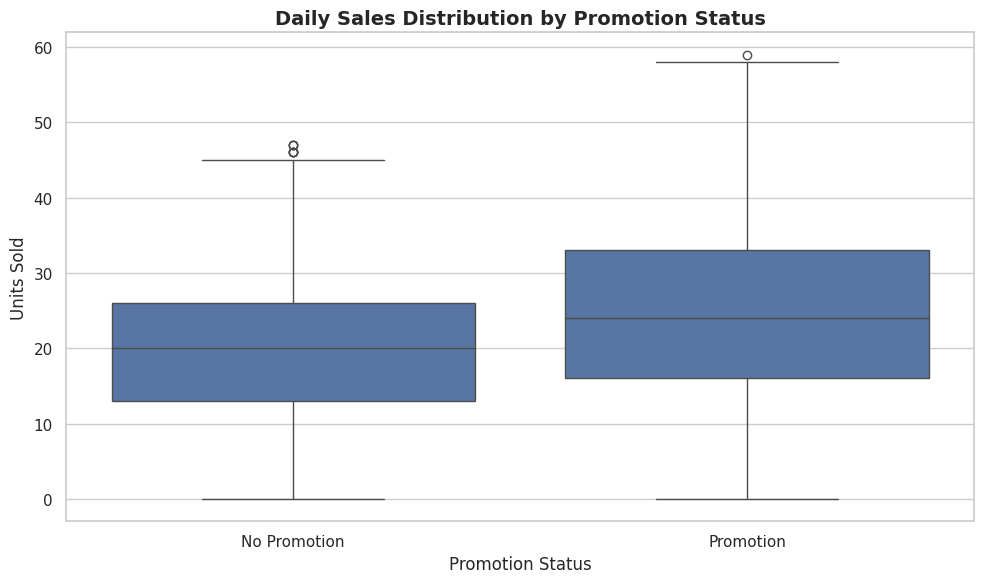

In [6]:

# ============================================================
# STEP 4C: VISUALISE SALES BY PROMOTION STATUS
# ============================================================

# Create a boxplot to compare daily sales distributions.
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df_promotion_analysis,
    x="Promotion_Status",
    y="Units_Sold"
)

# Add chart title and axis labels.
plt.title(
    "Daily Sales Distribution by Promotion Status",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Promotion Status")
plt.ylabel("Units Sold")

# Display the chart.
plt.tight_layout()
plt.show()


In [7]:

# ============================================================
# STEP 4D: EXAMINE PROMOTION VARIATION WITHIN SKU-WAREHOUSE GROUPS
# ============================================================

# Count promotion and non-promotion observations within each group.
promotion_group_summary = (
    df_promotion_analysis
    .groupby("SKU_Warehouse_Group")
    .agg(
        Total_Observations=("Promotion_Flag", "size"),
        Promotion_Observations=("Promotion_Flag", "sum"),
        Unique_Promotion_Values=("Promotion_Flag", "nunique")
    )
    .reset_index()
)

# Calculate the number of non-promotion observations.
promotion_group_summary["No_Promotion_Observations"] = (
    promotion_group_summary["Total_Observations"]
    - promotion_group_summary["Promotion_Observations"]
)

# Identify groups with both promotion and non-promotion observations.
promotion_group_summary["Has_Within_Group_Variation"] = (
    promotion_group_summary["Unique_Promotion_Values"] > 1
)

# Summarise the number of groups with and without variation.
groups_with_variation = (
    promotion_group_summary["Has_Within_Group_Variation"].sum()
)

groups_without_variation = (
    len(promotion_group_summary) - groups_with_variation
)

print("Total SKU-warehouse groups:", len(promotion_group_summary))
print("Groups with promotion variation:", groups_with_variation)
print("Groups without promotion variation:", groups_without_variation)

# Examine the distribution of promotion observations across groups.
display(
    promotion_group_summary[
        [
            "Total_Observations",
            "Promotion_Observations",
            "No_Promotion_Observations"
        ]
    ].describe().round(2)
)

# Display the first ten group-level records.
display(promotion_group_summary.head(10))

# Calculate the percentage of groups with within-group variation.
variation_percentage = (
    groups_with_variation / len(promotion_group_summary)
) * 100

print(
    "Percentage of groups with within-group promotion variation:",
    round(variation_percentage, 2),
    "%"
)


Total SKU-warehouse groups: 250
Groups with promotion variation: 250
Groups without promotion variation: 0


,Total_Observations,Promotion_Observations,No_Promotion_Observations
count,250.0,250.00,250.00
mean,365.0,37.08,327.92
std,0.0,5.60,5.60
min,365.0,19.00,312.00
25%,365.0,33.00,324.00
50%,365.0,37.00,328.00
75%,365.0,41.00,332.00
max,365.0,53.00,346.00


,SKU_Warehouse_Group,Total_Observations,Promotion_Observations,Unique_Promotion_Values,No_Promotion_Observations,Has_Within_Group_Variation
0,SKU_10_WH_1,365,37,2,328,True
1,SKU_10_WH_2,365,41,2,324,True
2,SKU_10_WH_3,365,41,2,324,True
3,SKU_10_WH_4,365,46,2,319,True
4,SKU_10_WH_5,365,34,2,331,True
5,SKU_11_WH_1,365,46,2,319,True
6,SKU_11_WH_2,365,37,2,328,True
7,SKU_11_WH_3,365,37,2,328,True
8,SKU_11_WH_4,365,27,2,338,True
9,SKU_11_WH_5,365,44,2,321,True


Percentage of groups with within-group promotion variation: 100.0 %


In [8]:

# ============================================================
# STEP 4E: FIXED-EFFECTS REGRESSION WITH CLUSTER-ROBUST ERRORS
# ============================================================

# Specify the regression model.
# C() tells Statsmodels to treat these variables as categories.
# SKU-warehouse fixed effects control for persistent group differences.
# Month fixed effects control for common monthly differences.

promotion_model = smf.ols(
    formula=(
        "Units_Sold ~ Promotion_Flag "
        "+ C(SKU_Warehouse_Group) "
        "+ C(Month)"
    ),
    data=df_promotion_analysis
)

# Fit the regression using cluster-robust standard errors.
# Clustering is performed at SKU-warehouse group level.
# This allows observations within a group to have correlated errors.

promotion_model_results = promotion_model.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df_promotion_analysis["SKU_Warehouse_Group"]
    }
)

# Display the complete regression results.
print(promotion_model_results.summary())


                            OLS Regression Results                            
Dep. Variable:             Units_Sold   R-squared:                       0.659
Model:                            OLS   Adj. R-squared:                  0.658
Method:                 Least Squares   F-statistic:                 1.781e+04
Date:                Fri, 20 Nov 2026   Prob (F-statistic):               0.00
Time:                        07:57:33   Log-Likelihood:            -2.8165e+05
No. Observations:               91250   AIC:                         5.638e+05
Df Residuals:                   90988   BIC:                         5.663e+05
Df Model:                         261                                         
Covariance Type:              cluster                                         
                                            coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------

/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 261, but rank is 12
  res = self.wald_test(


In [9]:

# ============================================================
# STEP 4F: EXTRACT KEY PROMOTION REGRESSION RESULTS
# ============================================================

# Extract the estimated promotion coefficient.
promotion_coefficient = (
    promotion_model_results.params["Promotion_Flag"]
)

# Extract the cluster-robust standard error.
promotion_standard_error = (
    promotion_model_results.bse["Promotion_Flag"]
)

# Extract the p-value.
promotion_p_value = (
    promotion_model_results.pvalues["Promotion_Flag"]
)

# Extract the 95% confidence interval.
promotion_confidence_interval = (
    promotion_model_results.conf_int().loc["Promotion_Flag"]
)

# Create a structured results table.
promotion_inference_results = pd.DataFrame({
    "Measure": [
        "Promotion Coefficient",
        "Cluster-Robust Standard Error",
        "P-value",
        "95% Confidence Interval Lower",
        "95% Confidence Interval Upper",
        "R-squared",
        "Adjusted R-squared",
        "Number of Observations",
        "Number of SKU-Warehouse Groups"
    ],
    "Value": [
        promotion_coefficient,
        promotion_standard_error,
        promotion_p_value,
        promotion_confidence_interval.iloc[0],
        promotion_confidence_interval.iloc[1],
        promotion_model_results.rsquared,
        promotion_model_results.rsquared_adj,
        int(promotion_model_results.nobs),
        df_promotion_analysis["SKU_Warehouse_Group"].nunique()
    ]
})

# Display the extracted results.
display(promotion_inference_results.round(6))

# Evaluate statistical significance at the 5% level.
significance_level = 0.05

if promotion_p_value < significance_level:
    print(
        "Statistical decision: Reject the null hypothesis "
        "at the 5% significance level."
    )
else:
    print(
        "Statistical decision: Fail to reject the null hypothesis "
        "at the 5% significance level."
    )


,Measure,Value
0,Promotion Coefficient,5.419697
1,Cluster-Robust Standard Error,0.072447
2,P-value,0.000000
3,95% Confidence Interval Lower,5.277703
4,95% Confidence Interval Upper,5.561690
5,R-squared,0.658511
6,Adjusted R-squared,0.657532
7,Number of Observations,91250.000000
8,Number of SKU-Warehouse Groups,250.000000


Statistical decision: Reject the null hypothesis at the 5% significance level.



## Robustness Check: Daily Fixed Effects

The initial regression controlled for SKU-warehouse group and calendar-month fixed effects.

A second regression is estimated using individual calendar-date fixed effects instead of month fixed effects.

This allows the model to control for common factors affecting observations on the same date.

Cluster-robust standard errors remain clustered at SKU-warehouse group level.

The purpose is to assess whether the estimated association between promotion status and daily sales remains stable under a more detailed time-control specification.


In [10]:

# ============================================================
# STEP 4G: REGRESSION WITH SKU-WAREHOUSE AND DAILY FIXED EFFECTS
# ============================================================

# Create a categorical date variable for daily fixed effects.
# Converting dates to strings makes their categorical treatment explicit.
df_promotion_analysis["Date_FE"] = (
    df_promotion_analysis["Date"].dt.strftime("%Y-%m-%d")
)

# Specify the robustness regression model.
# Individual date effects replace the previous calendar-month effects.
daily_fixed_effects_model = smf.ols(
    formula=(
        "Units_Sold ~ Promotion_Flag "
        "+ C(SKU_Warehouse_Group) "
        "+ C(Date_FE)"
    ),
    data=df_promotion_analysis
)

# Fit the model using cluster-robust standard errors.
# Clustering remains at SKU-warehouse group level.
daily_fixed_effects_results = daily_fixed_effects_model.fit(
    cov_type="cluster",
    cov_kwds={
        "groups": df_promotion_analysis["SKU_Warehouse_Group"]
    }
)

# Display only the key promotion coefficient information.
print("DAILY FIXED-EFFECTS ROBUSTNESS MODEL")
print("-------------------------------------")

print(
    "Promotion coefficient:",
    daily_fixed_effects_results.params["Promotion_Flag"]
)

print(
    "Cluster-robust standard error:",
    daily_fixed_effects_results.bse["Promotion_Flag"]
)

print(
    "P-value:",
    daily_fixed_effects_results.pvalues["Promotion_Flag"]
)

print(
    "95% confidence interval:",
    daily_fixed_effects_results.conf_int().loc["Promotion_Flag"].tolist()
)

print(
    "R-squared:",
    daily_fixed_effects_results.rsquared
)

print(
    "Number of observations:",
    int(daily_fixed_effects_results.nobs)
)


DAILY FIXED-EFFECTS ROBUSTNESS MODEL
-------------------------------------
Promotion coefficient: 5.400024207632233
Cluster-robust standard error: 0.07263974525753371
P-value: 0.0
95% confidence interval: [5.257652923081303, 5.5423954921831635]
R-squared: 0.6745162822298367
Number of observations: 91250


In [11]:

# ============================================================
# STEP 4H: COMPARE REGRESSION SPECIFICATIONS
# ============================================================

# Collect the promotion results from both models.
model_comparison = pd.DataFrame({
    "Model": [
        "SKU-Warehouse + Month Fixed Effects",
        "SKU-Warehouse + Daily Fixed Effects"
    ],
    "Promotion_Coefficient": [
        promotion_model_results.params["Promotion_Flag"],
        daily_fixed_effects_results.params["Promotion_Flag"]
    ],
    "Cluster_Robust_SE": [
        promotion_model_results.bse["Promotion_Flag"],
        daily_fixed_effects_results.bse["Promotion_Flag"]
    ],
    "P_Value": [
        promotion_model_results.pvalues["Promotion_Flag"],
        daily_fixed_effects_results.pvalues["Promotion_Flag"]
    ],
    "R_Squared": [
        promotion_model_results.rsquared,
        daily_fixed_effects_results.rsquared
    ]
})

# Calculate the difference between the two promotion coefficients.
coefficient_difference = (
    daily_fixed_effects_results.params["Promotion_Flag"]
    - promotion_model_results.params["Promotion_Flag"]
)

# Display the model comparison.
display(model_comparison.round(8))

print(
    "Difference between promotion coefficients:",
    round(coefficient_difference, 6)
)


,Model,Promotion_Coefficient,Cluster_Robust_SE,P_Value,R_Squared
0,SKU-Warehouse + Month Fixed Effects,5.419697,0.072447,0.0,0.658511
1,SKU-Warehouse + Daily Fixed Effects,5.400024,0.072640,0.0,0.674516


Difference between promotion coefficients: -0.019672


In [12]:

# ============================================================
# STEP 4J.1: EXTRACT AND SUMMARISE REGRESSION RESIDUALS
# ============================================================

# Create a copy of the analysis dataset for diagnostic work.
# This protects the original analysis DataFrame.
df_promotion_diagnostics = df_promotion_analysis.copy()

# Extract the predicted sales values from the daily fixed-effects model.
df_promotion_diagnostics["Predicted_Sales"] = (
    daily_fixed_effects_results.fittedvalues.to_numpy()
)

# Extract the residuals from the regression model.
# A residual is actual sales minus predicted sales.
df_promotion_diagnostics["Residual"] = (
    daily_fixed_effects_results.resid.to_numpy()
)

# Calculate the mean and standard deviation of the residuals.
residual_mean = df_promotion_diagnostics["Residual"].mean()
residual_std = df_promotion_diagnostics["Residual"].std()

# Calculate descriptive statistics for the residuals.
residual_summary = pd.DataFrame({
    "Statistic": [
        "Count",
        "Mean",
        "Standard Deviation",
        "Minimum",
        "25th Percentile",
        "Median",
        "75th Percentile",
        "Maximum",
        "Skewness",
        "Kurtosis"
    ],
    "Value": [
        df_promotion_diagnostics["Residual"].count(),
        residual_mean,
        residual_std,
        df_promotion_diagnostics["Residual"].min(),
        df_promotion_diagnostics["Residual"].quantile(0.25),
        df_promotion_diagnostics["Residual"].median(),
        df_promotion_diagnostics["Residual"].quantile(0.75),
        df_promotion_diagnostics["Residual"].max(),
        stats.skew(df_promotion_diagnostics["Residual"]),
        stats.kurtosis(df_promotion_diagnostics["Residual"])
    ]
})

# Identify residuals that are more than two or three standard
# deviations away from the residual mean.
outside_2_std = (
    df_promotion_diagnostics["Residual"].sub(residual_mean).abs()
    > 2 * residual_std
)

outside_3_std = (
    df_promotion_diagnostics["Residual"].sub(residual_mean).abs()
    > 3 * residual_std
)

# Calculate the number and percentage of observations
# outside each standard-deviation threshold.
residual_threshold_summary = pd.DataFrame({
    "Threshold": [
        "More than 2 standard deviations",
        "More than 3 standard deviations"
    ],
    "Number_of_Observations": [
        outside_2_std.sum(),
        outside_3_std.sum()
    ],
    "Percentage": [
        outside_2_std.mean() * 100,
        outside_3_std.mean() * 100
    ]
})

# Display the residual descriptive statistics.
print("RESIDUAL DESCRIPTIVE STATISTICS")
print("--------------------------------")
display(residual_summary.round(4))

# Display the residual threshold assessment.
print("\nRESIDUAL THRESHOLD ASSESSMENT")
print("-----------------------------")
display(residual_threshold_summary.round(4))


RESIDUAL DESCRIPTIVE STATISTICS
--------------------------------


,Statistic,Value
0,Count,91250.0000
1,Mean,-0.0000
2,Standard Deviation,5.1737
3,Minimum,-21.9383
4,25th Percentile,-3.5004
5,Median,-0.0195
6,75th Percentile,3.4585
7,Maximum,25.2581
8,Skewness,0.0412
9,Kurtosis,0.0804



RESIDUAL THRESHOLD ASSESSMENT
-----------------------------


,Threshold,Number_of_Observations,Percentage
0,More than 2 standard deviations,4125,4.5205
1,More than 3 standard deviations,283,0.3101


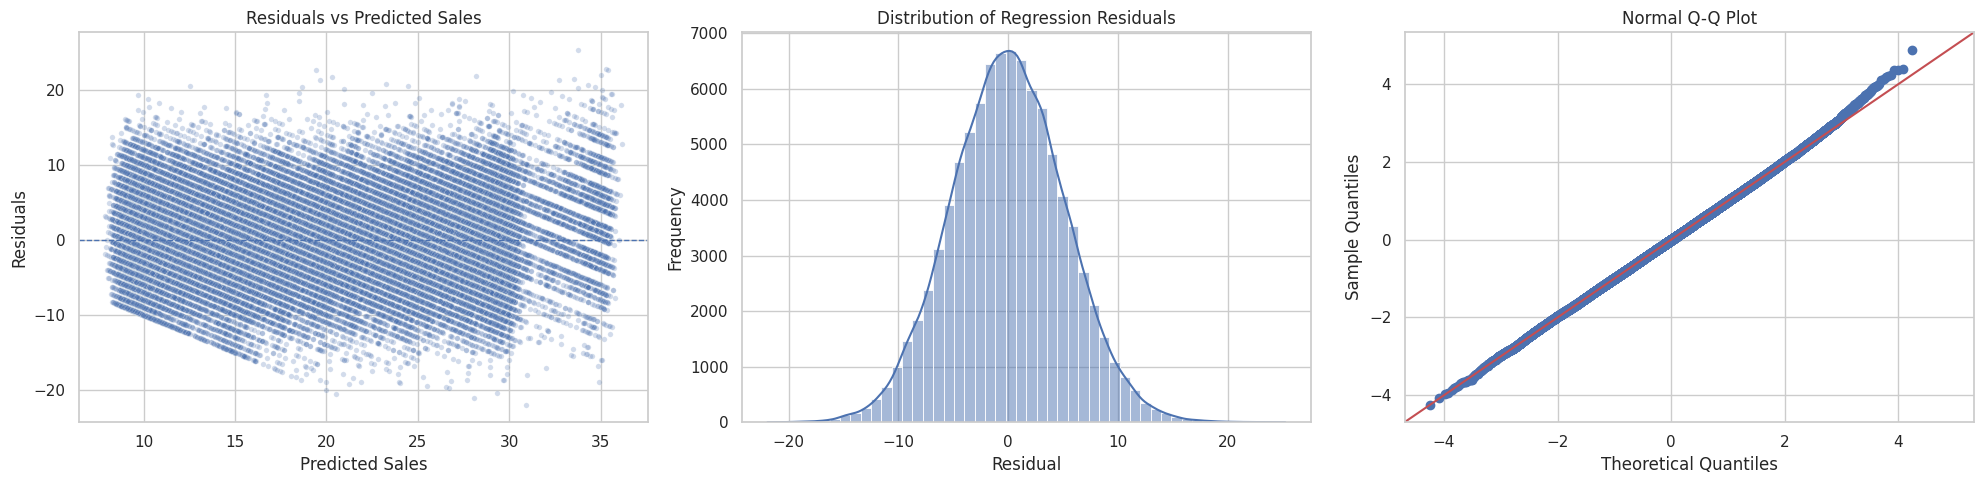

In [13]:

# ============================================================
# STEP 4J.2: VISUALISE REGRESSION RESIDUALS
# ============================================================

# Create a figure containing three diagnostic plots.
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# ------------------------------------------------------------
# PLOT 1: RESIDUALS AGAINST PREDICTED SALES
# ------------------------------------------------------------

# Plot residuals against the model's predicted sales values.
sns.scatterplot(
    data=df_promotion_diagnostics,
    x="Predicted_Sales",
    y="Residual",
    alpha=0.25,
    s=15,
    ax=axes[0]
)

# Add a horizontal reference line at zero residual.
axes[0].axhline(
    y=0,
    linestyle="--",
    linewidth=1
)

axes[0].set_title("Residuals vs Predicted Sales")
axes[0].set_xlabel("Predicted Sales")
axes[0].set_ylabel("Residuals")

# ------------------------------------------------------------
# PLOT 2: RESIDUAL DISTRIBUTION
# ------------------------------------------------------------

# Display the distribution of the regression residuals.
sns.histplot(
    data=df_promotion_diagnostics,
    x="Residual",
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Distribution of Regression Residuals")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frequency")

# ------------------------------------------------------------
# PLOT 3: NORMAL Q-Q PLOT
# ------------------------------------------------------------

# Compare the residual distribution with a theoretical
# normal distribution.
sm.qqplot(
    df_promotion_diagnostics["Residual"],
    line="45",
    fit=True,
    ax=axes[2]
)

axes[2].set_title("Normal Q-Q Plot")

# Adjust spacing to improve readability.
plt.tight_layout()

# Display all three diagnostic plots.
plt.show()


In [14]:

# ============================================================
# STEP 4J.3: BREUSCH-PAGAN HETEROSKEDASTICITY TEST
# ============================================================

# Prepare the explanatory variables for the test.
# The fitted values represent the systematic component
# estimated by the regression model.
bp_test_data = pd.DataFrame({
    "Predicted_Sales": daily_fixed_effects_results.fittedvalues
})

# Add a constant to the explanatory variable matrix.
# This is required for the auxiliary regression.
bp_test_exog = sm.add_constant(bp_test_data)

# Perform the Breusch-Pagan test.
# The test investigates whether residual variance is
# associated with the explanatory variables supplied.
bp_test = sm.stats.het_breuschpagan(
    daily_fixed_effects_results.resid,
    bp_test_exog
)

# Extract the test statistics and p-values.
bp_lm_statistic = bp_test[0]
bp_lm_p_value = bp_test[1]
bp_f_statistic = bp_test[2]
bp_f_p_value = bp_test[3]

# Organise the results into a readable table.
bp_results = pd.DataFrame({
    "Measure": [
        "LM Statistic",
        "LM-Test P-value",
        "F Statistic",
        "F-Test P-value"
    ],
    "Value": [
        bp_lm_statistic,
        bp_lm_p_value,
        bp_f_statistic,
        bp_f_p_value
    ]
})

# Display the Breusch-Pagan test results.
print("BREUSCH-PAGAN HETEROSKEDASTICITY TEST")
print("--------------------------------------")
display(bp_results.round(8))

# Interpret the result using a 5% significance level.
alpha = 0.05

if bp_lm_p_value < alpha:
    print(
        "Conclusion: Reject the null hypothesis. "
        "Evidence of heteroskedasticity was detected."
    )
else:
    print(
        "Conclusion: Fail to reject the null hypothesis. "
        "This test did not detect sufficient evidence "
        "of heteroskedasticity."
    )


BREUSCH-PAGAN HETEROSKEDASTICITY TEST
--------------------------------------


,Measure,Value
0,LM Statistic,173.215719
1,LM-Test P-value,0.000000
2,F Statistic,173.541348
3,F-Test P-value,0.000000


Conclusion: Reject the null hypothesis. Evidence of heteroskedasticity was detected.


In [15]:

# ============================================================
# STEP 4J.4: COMPARE STANDARD-ERROR SPECIFICATIONS
# ============================================================

# Fit the daily fixed-effects regression using conventional
# OLS standard errors.
daily_model_conventional = daily_fixed_effects_model.fit()

# Fit the same regression using HC1 heteroskedasticity-
# robust standard errors.
daily_model_hc1 = daily_fixed_effects_model.fit(
    cov_type="HC1"
)

# The existing daily_fixed_effects_results object already
# contains the model estimated with cluster-robust
# standard errors at SKU-Warehouse group level.

# Collect the promotion coefficient and uncertainty measures.
standard_error_comparison = pd.DataFrame({
    "Standard_Error_Method": [
        "Conventional OLS",
        "HC1 Robust",
        "SKU-Warehouse Cluster-Robust"
    ],
    "Promotion_Coefficient": [
        daily_model_conventional.params["Promotion_Flag"],
        daily_model_hc1.params["Promotion_Flag"],
        daily_fixed_effects_results.params["Promotion_Flag"]
    ],
    "Standard_Error": [
        daily_model_conventional.bse["Promotion_Flag"],
        daily_model_hc1.bse["Promotion_Flag"],
        daily_fixed_effects_results.bse["Promotion_Flag"]
    ],
    "P_Value": [
        daily_model_conventional.pvalues["Promotion_Flag"],
        daily_model_hc1.pvalues["Promotion_Flag"],
        daily_fixed_effects_results.pvalues["Promotion_Flag"]
    ]
})

# Calculate 95% confidence intervals for each specification.
confidence_intervals = [
    daily_model_conventional.conf_int().loc["Promotion_Flag"],
    daily_model_hc1.conf_int().loc["Promotion_Flag"],
    daily_fixed_effects_results.conf_int().loc["Promotion_Flag"]
]

# Add the confidence interval limits to the comparison table.
standard_error_comparison["CI_Lower_95"] = [
    interval.iloc[0] for interval in confidence_intervals
]

standard_error_comparison["CI_Upper_95"] = [
    interval.iloc[1] for interval in confidence_intervals
]

# Display the comparison.
print("STANDARD-ERROR ROBUSTNESS COMPARISON")
print("------------------------------------")

display(standard_error_comparison.round(8))


STANDARD-ERROR ROBUSTNESS COMPARISON
------------------------------------


,Standard_Error_Method,Promotion_Coefficient,Standard_Error,P_Value,CI_Lower_95,CI_Upper_95
0,Conventional OLS,5.400024,0.057075,0.0,5.288158,5.511891
1,HC1 Robust,5.400024,0.072175,0.0,5.258563,5.541485
2,SKU-Warehouse Cluster-Robust,5.400024,0.072640,0.0,5.257653,5.542395


### Step 4J.4: Comparison of Standard-Error Specifications

Three standard-error specifications were compared using the same daily fixed-effects regression model.

The promotion coefficient remained unchanged at approximately 5.4000 across all three specifications.

| Standard-error method | Standard error | 95% confidence interval |
|---|---:|---:|
| Conventional OLS | 0.0571 | [5.2882, 5.5119] |
| HC1 robust | 0.0722 | [5.2586, 5.5415] |
| SKU–warehouse cluster-robust | 0.0726 | [5.2577, 5.5424] |

All three specifications produced statistically significant positive promotion coefficients (p < 0.001).

The HC1 standard error was larger than the conventional OLS standard error, indicating that allowing for heteroskedasticity increased the estimated uncertainty.

The SKU–warehouse cluster-robust standard error was slightly larger than the HC1 standard error. This specification additionally accounts for arbitrary within-group error dependence, subject to the assumption that different SKU–warehouse clusters are independent.

**Conclusion:** The estimated positive association between promotion status and daily sales is robust to the three standard-error specifications. The preferred inference uses SKU–warehouse cluster-robust standard errors because the dataset contains repeated daily observations within 250 SKU–warehouse groups.

The results remain observational and should not be interpreted as evidence that promotions cause sales to increase.

In [16]:

# ============================================================
# STEP 4J.5: INVESTIGATE WITHIN-GROUP RESIDUAL AUTOCORRELATION
# ============================================================

# Create a diagnostic dataset containing the group identifiers,
# dates, and residuals from the daily fixed-effects model.
df_autocorrelation = df_promotion_diagnostics[
    ["SKU_ID", "Warehouse_ID", "Date", "Residual"]
].copy()

# Create a unique identifier for each SKU-warehouse group.
df_autocorrelation["SKU_Warehouse_Group"] = (
    df_autocorrelation["SKU_ID"].astype(str)
    + "_"
    + df_autocorrelation["Warehouse_ID"].astype(str)
)

# Sort observations chronologically within each group.
df_autocorrelation = df_autocorrelation.sort_values(
    ["SKU_Warehouse_Group", "Date"]
).reset_index(drop=True)

# Calculate the previous day's residual within each group.
# The shift operation does not carry residuals across groups.
df_autocorrelation["Previous_Day_Residual"] = (
    df_autocorrelation.groupby("SKU_Warehouse_Group")["Residual"]
    .shift(1)
)

# Remove the first observation of each group because it has
# no previous-day residual.
df_autocorrelation_pairs = df_autocorrelation.dropna(
    subset=["Previous_Day_Residual"]
).copy()

# Calculate the pooled correlation between consecutive
# residuals across all SKU-warehouse groups.
pooled_lag1_correlation = (
    df_autocorrelation_pairs["Residual"].corr(
        df_autocorrelation_pairs["Previous_Day_Residual"]
    )
)

# Calculate the lag-one correlation separately for each group.
group_lag1_correlations = (
    df_autocorrelation_pairs.groupby("SKU_Warehouse_Group")
    .apply(
        lambda group: group["Residual"].corr(
            group["Previous_Day_Residual"]
        ),
        include_groups=False
    )
    .rename("Lag1_Residual_Correlation")
    .reset_index()
)

# Summarise the distribution of group-specific correlations.
group_autocorrelation_summary = (
    group_lag1_correlations["Lag1_Residual_Correlation"]
    .describe()
    .to_frame(name="Value")
)

# Count groups with positive, negative, and near-zero
# lag-one residual correlations.
positive_groups = (
    group_lag1_correlations["Lag1_Residual_Correlation"] > 0
).sum()

negative_groups = (
    group_lag1_correlations["Lag1_Residual_Correlation"] < 0
).sum()

near_zero_groups = (
    group_lag1_correlations["Lag1_Residual_Correlation"].abs() < 0.05
).sum()

# Display the overall autocorrelation result.
print("POOLED LAG-ONE RESIDUAL CORRELATION")
print("-----------------------------------")
print(round(pooled_lag1_correlation, 6))

# Display the group-level correlation summary.
print("\nGROUP-LEVEL LAG-ONE CORRELATION SUMMARY")
print("---------------------------------------")
display(group_autocorrelation_summary.round(6))

# Display the distribution of group-level correlation signs.
print("\nGROUP-LEVEL AUTOCORRELATION COUNTS")
print("----------------------------------")

print("Number of SKU-Warehouse groups:",
      len(group_lag1_correlations))

print("Positive correlations:", positive_groups)
print("Negative correlations:", negative_groups)
print("Absolute correlation below 0.05:", near_zero_groups)

# Confirm the number of consecutive residual pairs.
print("\nNUMBER OF CONSECUTIVE RESIDUAL PAIRS")
print("------------------------------------")
print(len(df_autocorrelation_pairs))


POOLED LAG-ONE RESIDUAL CORRELATION
-----------------------------------
-0.008116

GROUP-LEVEL LAG-ONE CORRELATION SUMMARY
---------------------------------------


,Value
count,250.000000
mean,-0.008323
std,0.051004
min,-0.179580
25%,-0.039413
50%,-0.005745
75%,0.025457
max,0.149113



GROUP-LEVEL AUTOCORRELATION COUNTS
----------------------------------
Number of SKU-Warehouse groups: 250
Positive correlations: 116
Negative correlations: 134
Absolute correlation below 0.05: 171

NUMBER OF CONSECUTIVE RESIDUAL PAIRS
------------------------------------
91000


### Step 4J.5: Within-Group Residual Autocorrelation Assessment

Lag-one residual correlations were calculated to investigate whether regression errors were linearly associated across consecutive days within each SKU–warehouse group.

The analysis included 91,000 consecutive residual pairs across 250 SKU–warehouse groups.

**Pooled result:**
- Lag-one residual correlation: -0.008116.

**Group-level results:**
- Mean correlation: -0.008323.
- Median correlation: -0.005745.
- Minimum correlation: -0.179580.
- Maximum correlation: 0.149113.
- Standard deviation: 0.051004.
- Positive correlations: 116 groups.
- Negative correlations: 134 groups.
- Groups with absolute correlation below 0.05: 171 (68.4%).

**Interpretation:**

The pooled lag-one residual correlation was very close to zero, indicating a negligible overall linear relationship between consecutive residuals.

Most individual SKU–warehouse groups also displayed weak lag-one correlations. However, some groups showed stronger positive or negative relationships.

The pooled result should not be interpreted as proof that serial correlation is absent in every group, because positive and negative group-level correlations can offset one another.

**Conclusion:** The descriptive analysis did not reveal strong overall lag-one residual autocorrelation. SKU–warehouse cluster-robust standard errors remain the preferred inference method because they allow within-group error dependence, subject to independence between clusters and other relevant asymptotic assumptions.

**Limitation:** This assessment examines lag-one linear correlation only. It does not rule out higher-order autocorrelation, nonlinear dependence or cross-sectional dependence between different SKU–warehouse groups.

In [17]:

# ============================================================
# STEP 4J.6: HIGHER-ORDER WITHIN-GROUP RESIDUAL CORRELATION
# ============================================================

# Create a copy of the sorted residual diagnostic dataset.
df_higher_lags = df_autocorrelation.copy()

# Define the residual lags to investigate.
# Each lag represents the number of previous days.
residual_lags = [1, 2, 3, 7]

# Create an empty list to store the results.
lag_results = []

# Calculate residual correlations separately for each lag.
for lag in residual_lags:

    # Create a column containing the residual from the
    # specified number of previous days within each group.
    lag_column = f"Residual_Lag_{lag}"

    df_higher_lags[lag_column] = (
        df_higher_lags.groupby("SKU_Warehouse_Group")["Residual"]
        .shift(lag)
    )

    # Remove observations without a valid previous residual.
    valid_pairs = df_higher_lags.dropna(
        subset=[lag_column]
    )

    # Calculate the pooled correlation for this lag.
    pooled_correlation = (
        valid_pairs["Residual"].corr(
            valid_pairs[lag_column]
        )
    )

    # Calculate correlations separately for each group.
    group_correlations = (
        valid_pairs.groupby("SKU_Warehouse_Group")
        .apply(
            lambda group: group["Residual"].corr(
                group[lag_column]
            ),
            include_groups=False
        )
    )

    # Store the summary statistics for this lag.
    lag_results.append({
        "Lag_Days": lag,
        "Number_of_Pairs": len(valid_pairs),
        "Pooled_Correlation": pooled_correlation,
        "Mean_Group_Correlation": group_correlations.mean(),
        "Median_Group_Correlation": group_correlations.median(),
        "Minimum_Group_Correlation": group_correlations.min(),
        "Maximum_Group_Correlation": group_correlations.max(),
        "Groups_Positive": (group_correlations > 0).sum(),
        "Groups_Negative": (group_correlations < 0).sum()
    })

# Convert the results into a DataFrame.
higher_lag_summary = pd.DataFrame(lag_results)

# Display the higher-order autocorrelation results.
print("HIGHER-ORDER RESIDUAL AUTOCORRELATION")
print("-------------------------------------")

display(higher_lag_summary.round(6))


HIGHER-ORDER RESIDUAL AUTOCORRELATION
-------------------------------------


,Lag_Days,Number_of_Pairs,Pooled_Correlation,Mean_Group_Correlation,Median_Group_Correlation,Minimum_Group_Correlation,Maximum_Group_Correlation,Groups_Positive,Groups_Negative
0,1,91000,-0.008116,-0.008323,-0.005745,-0.179580,0.149113,116,134
1,2,90750,-0.009582,-0.009169,-0.006555,-0.161359,0.122526,117,133
2,3,90500,-0.005247,-0.005359,-0.003878,-0.183323,0.111285,119,131
3,7,89500,0.001291,0.001525,0.003306,-0.134294,0.208803,131,119


### Step 4J.6: Higher-Order Residual Autocorrelation Analysis

Residual autocorrelation was investigated at lags of 1, 2, 3 and 7 days within the 250 SKU–warehouse groups.

The pooled residual correlations were:

| Lag | Pooled correlation |
|---|---:|
| 1 day | -0.008116 |
| 2 days | -0.009582 |
| 3 days | -0.005247 |
| 7 days | 0.001291 |

The mean and median group-level correlations were also close to zero across all four lags.

At lag one, 116 groups had positive correlations and 134 had negative correlations. At lag seven, 131 groups had positive correlations and 119 had negative correlations.

Most groups displayed weak lag-one correlations, with 171 of the 250 groups having an absolute correlation below 0.05.

However, some individual groups displayed larger correlations, indicating that temporal dependence may vary across SKU–warehouse combinations.

**Conclusion:** The pooled results do not indicate strong systematic linear residual autocorrelation at the investigated lags. Nevertheless, the group-level variation means that autocorrelation should not be assumed to be completely absent.

The analysis is descriptive and does not constitute a formal statistical test of serial independence.

In [18]:

# ============================================================
# STEP 4J.7: GROUP-LEVEL LJUNG-BOX AUTOCORRELATION TESTS
# ============================================================

# Import the Ljung-Box test and multiple-testing correction.
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.multitest import multipletests

# Create a list to store the test results for each group.
ljung_box_results = []

# Conduct a separate Ljung-Box test for each SKU-warehouse group.
for group_name, group_data in df_autocorrelation.groupby(
    "SKU_Warehouse_Group"
):

    # Sort residuals chronologically within the group.
    residual_series = group_data.sort_values("Date")["Residual"]

    # Test residual autocorrelation jointly through lag 7.
    # The test evaluates whether autocorrelations up to lag 7
    # are jointly different from zero.
    test_result = acorr_ljungbox(
        residual_series,
        lags=[7],
        return_df=True
    )

    # Store the group identifier, test statistic and p-value.
    ljung_box_results.append({
        "SKU_Warehouse_Group": group_name,
        "Ljung_Box_Statistic": test_result["lb_stat"].iloc[0],
        "P_Value": test_result["lb_pvalue"].iloc[0]
    })

# Convert the results into a DataFrame.
ljung_box_summary = pd.DataFrame(ljung_box_results)

# Apply the Benjamini-Hochberg correction to the 250 p-values.
# This controls the expected false discovery rate.
rejection_results, adjusted_p_values, _, _ = multipletests(
    ljung_box_summary["P_Value"],
    alpha=0.05,
    method="fdr_bh"
)

# Add adjusted p-values and significance decisions.
ljung_box_summary["Adjusted_P_Value"] = adjusted_p_values

ljung_box_summary["Significant_After_Correction"] = (
    rejection_results
)

# Count groups with significant results before and after correction.
significant_before_correction = (
    ljung_box_summary["P_Value"] < 0.05
).sum()

significant_after_correction = (
    ljung_box_summary["Significant_After_Correction"].sum()
)

# Calculate the percentage of groups with significant results.
percentage_after_correction = (
    significant_after_correction
    / len(ljung_box_summary)
    * 100
)

# Summarise the results.
ljung_box_overview = pd.DataFrame({
    "Measure": [
        "Number of SKU-Warehouse Groups",
        "Significant Before Correction",
        "Significant After Benjamini-Hochberg Correction",
        "Percentage Significant After Correction"
    ],
    "Value": [
        len(ljung_box_summary),
        significant_before_correction,
        significant_after_correction,
        percentage_after_correction
    ]
})

# Display the overall test summary.
print("GROUP-LEVEL LJUNG-BOX TEST SUMMARY")
print("-----------------------------------")
display(ljung_box_overview.round(4))

# Display the groups with the smallest adjusted p-values.
print("\nTEN GROUPS WITH THE SMALLEST ADJUSTED P-VALUES")
print("----------------------------------------------")

display(
    ljung_box_summary.sort_values(
        "Adjusted_P_Value"
    ).head(10).round(8)
)


GROUP-LEVEL LJUNG-BOX TEST SUMMARY
-----------------------------------


,Measure,Value
0,Number of SKU-Warehouse Groups,250.0
1,Significant Before Correction,10.0
2,Significant After Benjamini-Hochberg Correction,0.0
3,Percentage Significant After Correction,0.0



TEN GROUPS WITH THE SMALLEST ADJUSTED P-VALUES
----------------------------------------------


,SKU_Warehouse_Group,Ljung_Box_Statistic,P_Value,Adjusted_P_Value,Significant_After_Correction
21,SKU_14_WH_2,23.289000,0.001518,0.313821,False
197,SKU_46_WH_3,22.029767,0.002511,0.313821,False
6,SKU_11_WH_2,6.544414,0.477802,0.958020,False
3,SKU_10_WH_4,7.063164,0.422333,0.958020,False
12,SKU_12_WH_3,6.205201,0.516004,0.958020,False
13,SKU_12_WH_4,7.086183,0.419962,0.958020,False
15,SKU_13_WH_1,5.778175,0.565876,0.958020,False
4,SKU_10_WH_5,10.205715,0.177212,0.958020,False
25,SKU_15_WH_1,8.533583,0.287898,0.958020,False
26,SKU_15_WH_2,6.455224,0.487710,0.958020,False


### Step 4J.7: Group-Level Ljung–Box Autocorrelation Tests

The Ljung–Box test was conducted separately for each of the 250 SKU–warehouse groups to investigate residual autocorrelation jointly through lag seven.

The initial results identified 10 groups with p-values below 0.05.

However, after applying the Benjamini–Hochberg false discovery rate correction, none of the 250 groups remained statistically significant at the 5% level.

The two groups with the smallest original p-values were:

| SKU–warehouse group | Ljung–Box statistic | Original p-value | Adjusted p-value |
|---|---:|---:|---:|
| SKU_14_WH_2 | 23.2890 | 0.001518 | 0.313821 |
| SKU_46_WH_3 | 22.0298 | 0.002511 | 0.313821 |

**Conclusion:** After accounting for multiple hypothesis testing, the analysis did not identify statistically significant residual autocorrelation through lag seven in any of the 250 groups.

This finding is consistent with the earlier descriptive autocorrelation results, which showed pooled correlations close to zero.

However, failure to reject the null hypotheses does not prove that residuals are independent. The test does not address all possible forms of temporal dependence or cross-sectional dependence between different SKU–warehouse groups.

In [19]:

# ============================================================
# STEP 4J.8: PESARAN CROSS-SECTIONAL DEPENDENCE TEST
# ============================================================

# Import the standard normal distribution for calculating
# the two-sided p-value.
from scipy.stats import norm

# Arrange the regression residuals into a panel structure.
# Each row represents a SKU-warehouse group.
# Each column represents an observation date.
residual_matrix = df_autocorrelation.pivot(
    index="SKU_Warehouse_Group",
    columns="Date",
    values="Residual"
)

# Calculate the number of groups and observation dates.
number_of_groups = residual_matrix.shape[0]
number_of_dates = residual_matrix.shape[1]

# Calculate pairwise correlations between group residual series.
# Each correlation measures whether two groups' residuals
# move together across the observed dates.
cross_sectional_correlations = residual_matrix.T.corr()

# Extract the upper triangle of the correlation matrix.
# This prevents counting each pair twice and excludes
# correlations of each group with itself.
upper_triangle = np.triu(
    cross_sectional_correlations.to_numpy(),
    k=1
)

pairwise_correlations = upper_triangle[
    np.triu_indices(number_of_groups, k=1)
]

# Calculate the number of unique group pairs.
number_of_pairs = len(pairwise_correlations)

# Calculate the Pesaran CD statistic.
# The statistic uses the sum of pairwise residual correlations.
pesaran_cd_statistic = (
    np.sqrt(
        2 * number_of_dates
        / (number_of_groups * (number_of_groups - 1))
    )
    * pairwise_correlations.sum()
)

# Calculate the two-sided p-value using the standard
# normal reference distribution.
pesaran_cd_p_value = (
    2 * norm.sf(abs(pesaran_cd_statistic))
)

# Calculate descriptive summaries of the pairwise correlations.
pairwise_correlation_summary = pd.DataFrame({
    "Measure": [
        "Number of SKU-Warehouse Groups",
        "Number of Dates",
        "Number of Unique Group Pairs",
        "Mean Pairwise Correlation",
        "Median Pairwise Correlation",
        "Minimum Pairwise Correlation",
        "Maximum Pairwise Correlation",
        "Pesaran CD Statistic",
        "Pesaran CD P-value"
    ],
    "Value": [
        number_of_groups,
        number_of_dates,
        number_of_pairs,
        np.mean(pairwise_correlations),
        np.median(pairwise_correlations),
        np.min(pairwise_correlations),
        np.max(pairwise_correlations),
        pesaran_cd_statistic,
        pesaran_cd_p_value
    ]
})

# Display the cross-sectional dependence results.
print("PESARAN CROSS-SECTIONAL DEPENDENCE TEST")
print("---------------------------------------")
display(pairwise_correlation_summary.round(8))

# Interpret the result at the 5% significance level.
if pesaran_cd_p_value < 0.05:
    print(
        "Conclusion: Reject the null hypothesis. "
        "Evidence of cross-sectional dependence was detected."
    )
else:
    print(
        "Conclusion: Fail to reject the null hypothesis. "
        "The test did not detect sufficient evidence "
        "of cross-sectional dependence."
    )


PESARAN CROSS-SECTIONAL DEPENDENCE TEST
---------------------------------------


,Measure,Value
0,Number of SKU-Warehouse Groups,250.000000
1,Number of Dates,365.000000
2,Number of Unique Group Pairs,31125.000000
3,Mean Pairwise Correlation,-0.004010
4,Median Pairwise Correlation,-0.004054
5,Minimum Pairwise Correlation,-0.212375
6,Maximum Pairwise Correlation,0.232825
7,Pesaran CD Statistic,-13.515680
8,Pesaran CD P-value,0.000000


Conclusion: Reject the null hypothesis. Evidence of cross-sectional dependence was detected.


In [21]:

# Import the two-way cluster-robust covariance function.
from statsmodels.stats.sandwich_covariance import cov_cluster_2groups

# Create numeric identifiers for the SKU-Warehouse groups.
# Each unique group receives its own integer identifier.
group_codes = pd.factorize(
    df_promotion_analysis["SKU_Warehouse_Group"]
)[0]

# Create numeric identifiers for the dates.
# Each unique date receives its own integer identifier.
date_codes = pd.factorize(
    df_promotion_analysis["Date"]
)[0]

# Fit the existing daily fixed-effects model using conventional OLS.
# The regression formula and observations remain unchanged.
daily_fixed_effects_ols = daily_fixed_effects_model.fit()

# Calculate two-way cluster-robust covariance.
# First dimension: SKU-Warehouse group.
# Second dimension: Date.
two_way_covariance, group_covariance, date_covariance = (
    cov_cluster_2groups(
        daily_fixed_effects_ols,
        group_codes,
        date_codes
    )
)

# Identify the position of the Promotion_Flag coefficient.
promotion_index = (
    daily_fixed_effects_ols.model.exog_names.index(
        "Promotion_Flag"
    )
)

# Extract the promotion coefficient.
promotion_coefficient = (
    daily_fixed_effects_ols.params["Promotion_Flag"]
)

# Calculate the two-way cluster-robust standard error.
promotion_two_way_se = np.sqrt(
    two_way_covariance[
        promotion_index,
        promotion_index
    ]
)

# Calculate the test statistic using a normal approximation.
promotion_z_statistic = (
    promotion_coefficient / promotion_two_way_se
)

# Calculate the two-sided p-value.
promotion_two_way_p = (
    2 * stats.norm.sf(abs(promotion_z_statistic))
)

# Calculate the 95% confidence interval.
promotion_ci_lower = (
    promotion_coefficient - 1.96 * promotion_two_way_se
)

promotion_ci_upper = (
    promotion_coefficient + 1.96 * promotion_two_way_se
)

# Organise the results into a readable table.
two_way_results = pd.DataFrame({
    "Measure": [
        "Promotion Coefficient",
        "Two-Way Cluster-Robust SE",
        "Test Statistic",
        "P-value",
        "95% CI Lower",
        "95% CI Upper"
    ],
    "Value": [
        promotion_coefficient,
        promotion_two_way_se,
        promotion_z_statistic,
        promotion_two_way_p,
        promotion_ci_lower,
        promotion_ci_upper
    ]
})

# Display the results.
print("TWO-WAY CLUSTER-ROBUST REGRESSION RESULTS")
print("------------------------------------------")
display(two_way_results)

# Confirm the number of clusters in each dimension.
print("CLUSTER COUNTS")
print("--------------")
print("SKU-Warehouse groups:", len(np.unique(group_codes)))
print("Unique dates:", len(np.unique(date_codes)))


TWO-WAY CLUSTER-ROBUST REGRESSION RESULTS
------------------------------------------


,Measure,Value
0,Promotion Coefficient,5.400024
1,Two-Way Cluster-Robust SE,0.139660
2,Test Statistic,38.665403
3,P-value,0.000000
4,95% CI Lower,5.126290
5,95% CI Upper,5.673759


CLUSTER COUNTS
--------------
SKU-Warehouse groups: 250
Unique dates: 365


In [22]:

# Import the Student's t-distribution.
from scipy.stats import t

# Determine the number of clusters in each dimension.
number_of_group_clusters = len(np.unique(group_codes))
number_of_date_clusters = len(np.unique(date_codes))

# Use the smaller cluster count minus one as the
# conservative degrees-of-freedom approximation.
cluster_degrees_of_freedom = (
    min(number_of_group_clusters, number_of_date_clusters) - 1
)

# Calculate the t-statistic using the two-way clustered SE.
promotion_t_statistic = (
    promotion_coefficient / promotion_two_way_se
)

# Calculate the two-sided p-value using the t-distribution.
promotion_t_p_value = (
    2 * t.sf(
        abs(promotion_t_statistic),
        df=cluster_degrees_of_freedom
    )
)

# Calculate the critical t-value for a 95% confidence interval.
critical_t_value = t.ppf(
    0.975,
    df=cluster_degrees_of_freedom
)

# Calculate the finite-cluster 95% confidence interval.
promotion_t_ci_lower = (
    promotion_coefficient
    - critical_t_value * promotion_two_way_se
)

promotion_t_ci_upper = (
    promotion_coefficient
    + critical_t_value * promotion_two_way_se
)

# Organise the results into a table.
finite_cluster_results = pd.DataFrame({
    "Measure": [
        "Promotion Coefficient",
        "Two-Way Cluster-Robust SE",
        "Degrees of Freedom",
        "Critical t-Value",
        "t-Statistic",
        "P-value",
        "95% CI Lower",
        "95% CI Upper"
    ],
    "Value": [
        promotion_coefficient,
        promotion_two_way_se,
        cluster_degrees_of_freedom,
        critical_t_value,
        promotion_t_statistic,
        promotion_t_p_value,
        promotion_t_ci_lower,
        promotion_t_ci_upper
    ]
})

# Display the finite-cluster inference results.
print("FINITE-CLUSTER INFERENCE CHECK")
print("--------------------------------")
display(finite_cluster_results)


FINITE-CLUSTER INFERENCE CHECK
--------------------------------


,Measure,Value
0,Promotion Coefficient,5.400024e+00
1,Two-Way Cluster-Robust SE,1.396604e-01
2,Degrees of Freedom,2.490000e+02
3,Critical t-Value,1.969537e+00
4,t-Statistic,3.866540e+01
5,P-value,3.093395e-107
6,95% CI Lower,5.124958e+00
7,95% CI Upper,5.675090e+00


### Step 4J.10: Finite-Cluster Inference Check

A finite-cluster inference check was performed using a Student's t-distribution, with degrees of freedom approximated as the smaller of the two cluster counts minus one.

The analysis used:

- 250 SKU-Warehouse clusters.
- 365 date clusters.
- 249 approximate degrees of freedom.

The promotion coefficient was 5.400024, with a two-way cluster-robust standard error of 0.139660.

The resulting t-statistic was 38.665403, with a p-value of approximately 3.09 × 10⁻¹⁰⁷. The approximate 95% confidence interval was [5.124958, 5.675090].

**Interpretation:**

The positive association between promotion status and daily units sold remains statistically significant using this finite-cluster approximation. The confidence interval remains entirely above zero.

The smaller-cluster-minus-one degrees-of-freedom approach is an approximation rather than an exact finite-sample correction for every two-way clustered design. This limitation should be considered when interpreting the inferential results.

**Final conclusion for Research Question 1:**

After controlling for SKU-Warehouse fixed effects and daily fixed effects, promotion observations are associated with approximately 5.40 additional units sold per day. This association remains statistically significant under two-way cluster-robust inference.

The analysis does not establish causation. Promotion assignment was not random, and other unobserved factors may contribute to the observed difference.

In [23]:

# Create a separate working copy for the inventory and sales analysis.
# This preserves the original dataframe.
df_inventory_analysis = df.copy()

# Ensure observations are ordered chronologically within each
# SKU-Warehouse combination.
df_inventory_analysis = df_inventory_analysis.sort_values(
    ["SKU_ID", "Warehouse_ID", "Date"]
).reset_index(drop=True)

# Create a unique identifier for each SKU-Warehouse combination.
df_inventory_analysis["SKU_Warehouse_Group"] = (
    df_inventory_analysis["SKU_ID"].astype(str)
    + "_"
    + df_inventory_analysis["Warehouse_ID"].astype(str)
)

# Calculate the previous day's recorded inventory within each group.
# This prevents inventory from one group being assigned to another.
df_inventory_analysis["Beginning_Inventory_Proxy"] = (
    df_inventory_analysis.groupby(
        "SKU_Warehouse_Group"
    )["Inventory_Level"].shift(1)
)

# Display the first observations to inspect the lag calculation.
print("INVENTORY ANALYSIS DATASET")
print("--------------------------")

display(
    df_inventory_analysis[
        [
            "Date",
            "SKU_ID",
            "Warehouse_ID",
            "Units_Sold",
            "Inventory_Level",
            "Beginning_Inventory_Proxy"
        ]
    ].head(10)
)

# Check the resulting dataset dimensions and missing values.
print("DATASET DIMENSIONS:", df_inventory_analysis.shape)

print(
    "MISSING BEGINNING INVENTORY PROXY:",
    df_inventory_analysis["Beginning_Inventory_Proxy"].isna().sum()
)

# Count observations available for the analysis.
print(
    "VALID OBSERVATIONS:",
    df_inventory_analysis["Beginning_Inventory_Proxy"].notna().sum()
)


INVENTORY ANALYSIS DATASET
--------------------------


,Date,SKU_ID,Warehouse_ID,Units_Sold,Inventory_Level,Beginning_Inventory_Proxy
0,2024-01-01,SKU_1,WH_1,10,592,NaN
1,2024-01-02,SKU_1,WH_1,17,575,592.0
2,2024-01-03,SKU_1,WH_1,35,540,575.0
3,2024-01-04,SKU_1,WH_1,24,516,540.0
4,2024-01-05,SKU_1,WH_1,21,495,516.0
5,2024-01-06,SKU_1,WH_1,18,477,495.0
6,2024-01-07,SKU_1,WH_1,19,458,477.0
7,2024-01-08,SKU_1,WH_1,23,435,458.0
8,2024-01-09,SKU_1,WH_1,25,410,435.0
9,2024-01-10,SKU_1,WH_1,25,385,410.0


DATASET DIMENSIONS: (91250, 17)
MISSING BEGINNING INVENTORY PROXY: 250
VALID OBSERVATIONS: 91000


In [24]:

# Select observations with valid beginning-inventory values.
# The first observation in each SKU-Warehouse group is excluded.
df_inventory_valid = df_inventory_analysis.dropna(
    subset=["Beginning_Inventory_Proxy"]
).copy()

# Define the two variables for this research question.
inventory_sales_variables = [
    "Beginning_Inventory_Proxy",
    "Units_Sold"
]

# Calculate descriptive statistics for both variables.
inventory_sales_descriptive = (
    df_inventory_valid[inventory_sales_variables]
    .describe()
    .T
)

# Calculate skewness to assess distribution asymmetry.
inventory_sales_descriptive["Skewness"] = (
    df_inventory_valid[inventory_sales_variables].skew()
)

# Calculate excess kurtosis to describe distribution tails.
inventory_sales_descriptive["Excess_Kurtosis"] = (
    df_inventory_valid[inventory_sales_variables].kurtosis()
)

# Display the descriptive statistics.
print("BEGINNING INVENTORY AND DAILY SALES: DESCRIPTIVE STATISTICS")
print("------------------------------------------------------------")
display(inventory_sales_descriptive)

# Confirm the number of observations used.
print(
    "OBSERVATIONS USED:",
    len(df_inventory_valid)
)


BEGINNING INVENTORY AND DAILY SALES: DESCRIPTIVE STATISTICS
------------------------------------------------------------


,count,mean,std,min,25%,50%,75%,max,Skewness,Excess_Kurtosis
Beginning_Inventory_Proxy,91000.0,471.564747,133.514715,168.0,370.0,461.0,564.0,990.0,0.329565,-0.389905
Units_Sold,91000.0,20.054121,9.076524,0.0,13.0,20.0,27.0,59.0,0.137134,-0.459829


OBSERVATIONS USED: 91000


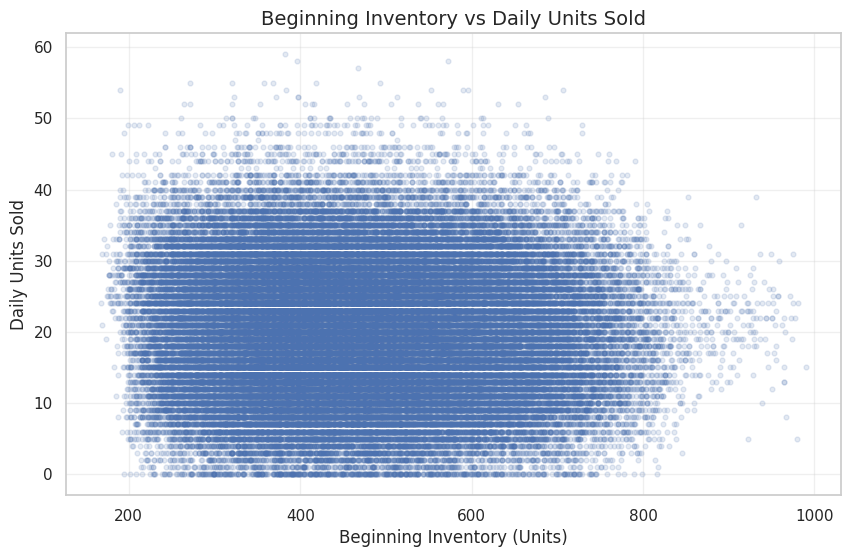

In [25]:

# Create a scatter plot to examine the relationship between
# beginning inventory and daily units sold.

plt.figure(figsize=(10, 6))

# Plot beginning inventory against daily sales.
plt.scatter(
    df_inventory_valid["Beginning_Inventory_Proxy"],
    df_inventory_valid["Units_Sold"],
    alpha=0.15,
    s=12
)

# Add descriptive chart labels.
plt.title(
    "Beginning Inventory vs Daily Units Sold",
    fontsize=14
)

plt.xlabel("Beginning Inventory (Units)")
plt.ylabel("Daily Units Sold")

# Add a grid to improve readability.
plt.grid(alpha=0.3)

# Display the chart.
plt.show()


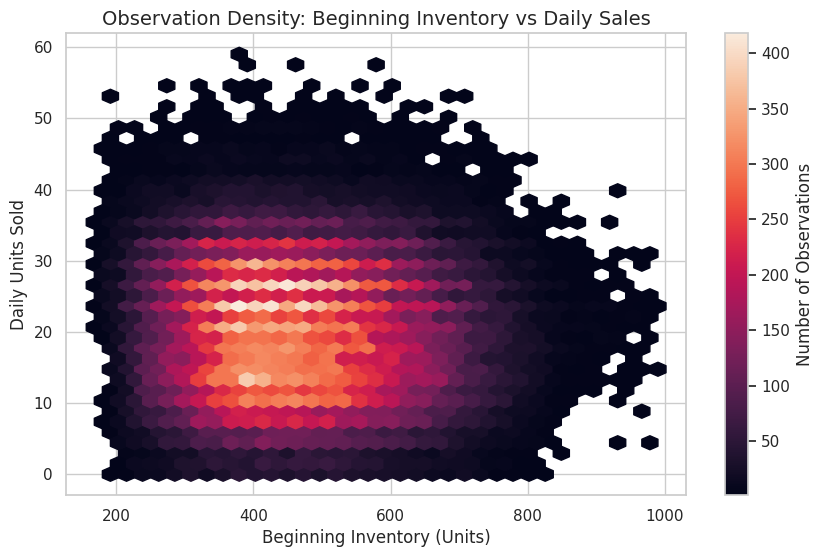

In [26]:

# Create a hexbin plot to show the concentration of observations.
# This is useful when many points overlap in a scatter plot.

plt.figure(figsize=(10, 6))

# Plot the density of observations using hexagonal bins.
plt.hexbin(
    df_inventory_valid["Beginning_Inventory_Proxy"],
    df_inventory_valid["Units_Sold"],
    gridsize=35,
    mincnt=1
)

# Add a colour bar to indicate the number of observations per bin.
plt.colorbar(label="Number of Observations")

# Add chart labels.
plt.title(
    "Observation Density: Beginning Inventory vs Daily Sales",
    fontsize=14
)

plt.xlabel("Beginning Inventory (Units)")
plt.ylabel("Daily Units Sold")

# Display the chart.
plt.show()


In [27]:

# Calculate Pearson correlation to assess linear association.
pearson_correlation, pearson_p_value = stats.pearsonr(
    df_inventory_valid["Beginning_Inventory_Proxy"],
    df_inventory_valid["Units_Sold"]
)

# Calculate Spearman correlation to assess monotonic association.
spearman_correlation, spearman_p_value = stats.spearmanr(
    df_inventory_valid["Beginning_Inventory_Proxy"],
    df_inventory_valid["Units_Sold"]
)

# Organise correlation results into a comparison table.
inventory_sales_correlations = pd.DataFrame({
    "Correlation_Method": [
        "Pearson",
        "Spearman"
    ],
    "Correlation_Coefficient": [
        pearson_correlation,
        spearman_correlation
    ],
    "P_Value": [
        pearson_p_value,
        spearman_p_value
    ]
})

# Display the results.
print("INVENTORY AND DAILY SALES: CORRELATION ANALYSIS")
print("------------------------------------------------")
display(inventory_sales_correlations)

# Display the number of observations used.
print(
    "OBSERVATIONS:",
    len(df_inventory_valid)
)


INVENTORY AND DAILY SALES: CORRELATION ANALYSIS
------------------------------------------------


,Correlation_Method,Correlation_Coefficient,P_Value
0,Pearson,-0.039308,1.861648e-32
1,Spearman,-0.038820,1.069986e-31


OBSERVATIONS: 91000


In [28]:

# Create a separate copy for the fixed-effects regression.
df_inventory_model = df_inventory_valid.copy()

# Create a string date identifier for the daily fixed effects.
df_inventory_model["Date_FE"] = (
    df_inventory_model["Date"].dt.strftime("%Y-%m-%d")
)

# Define the fixed-effects regression.
# Beginning inventory is the explanatory variable.
# Daily sales is the dependent variable.
# SKU-Warehouse and date fixed effects control for group
# differences and common daily effects.
inventory_sales_model = smf.ols(
    formula=(
        "Units_Sold ~ Beginning_Inventory_Proxy "
        "+ C(SKU_Warehouse_Group) "
        "+ C(Date_FE)"
    ),
    data=df_inventory_model
)

# Estimate the model using ordinary least squares.
inventory_sales_ols = inventory_sales_model.fit()

# Create numeric cluster identifiers for the valid observations.
# These identifiers must align with the regression dataset.
inventory_group_codes = pd.factorize(
    df_inventory_model["SKU_Warehouse_Group"]
)[0]

inventory_date_codes = pd.factorize(
    df_inventory_model["Date"]
)[0]

# Calculate two-way cluster-robust covariance.
inventory_two_way_covariance, inventory_group_covariance, inventory_date_covariance = (
    cov_cluster_2groups(
        inventory_sales_ols,
        inventory_group_codes,
        inventory_date_codes
    )
)

# Find the position of the beginning-inventory coefficient.
inventory_coefficient_index = (
    inventory_sales_ols.model.exog_names.index(
        "Beginning_Inventory_Proxy"
    )
)

# Extract the estimated coefficient.
inventory_coefficient = (
    inventory_sales_ols.params["Beginning_Inventory_Proxy"]
)

# Calculate the two-way cluster-robust standard error.
inventory_two_way_se = np.sqrt(
    inventory_two_way_covariance[
        inventory_coefficient_index,
        inventory_coefficient_index
    ]
)

# Calculate the test statistic using a normal approximation.
inventory_z_statistic = (
    inventory_coefficient / inventory_two_way_se
)

# Calculate the two-sided p-value.
inventory_p_value = (
    2 * stats.norm.sf(abs(inventory_z_statistic))
)

# Calculate the 95% confidence interval using a normal approximation.
inventory_ci_lower = (
    inventory_coefficient - 1.96 * inventory_two_way_se
)

inventory_ci_upper = (
    inventory_coefficient + 1.96 * inventory_two_way_se
)

# Organise the model results into a table.
inventory_model_results = pd.DataFrame({
    "Measure": [
        "Beginning Inventory Coefficient",
        "Two-Way Cluster-Robust SE",
        "Test Statistic",
        "P-value",
        "95% CI Lower",
        "95% CI Upper",
        "R-squared",
        "Adjusted R-squared",
        "Observations"
    ],
    "Value": [
        inventory_coefficient,
        inventory_two_way_se,
        inventory_z_statistic,
        inventory_p_value,
        inventory_ci_lower,
        inventory_ci_upper,
        inventory_sales_ols.rsquared,
        inventory_sales_ols.rsquared_adj,
        int(inventory_sales_ols.nobs)
    ]
})

# Display the regression results.
print("INVENTORY AND DAILY SALES: FIXED-EFFECTS REGRESSION")
print("---------------------------------------------------")
display(inventory_model_results)

# Confirm the clustering dimensions.
print("SKU-WAREHOUSE CLUSTERS:", len(np.unique(inventory_group_codes)))
print("DATE CLUSTERS:", len(np.unique(inventory_date_codes)))


INVENTORY AND DAILY SALES: FIXED-EFFECTS REGRESSION
---------------------------------------------------


,Measure,Value
0,Beginning Inventory Coefficient,-0.000196
1,Two-Way Cluster-Robust SE,0.000169
2,Test Statistic,-1.155282
3,P-value,0.247975
4,95% CI Lower,-0.000528
5,95% CI Upper,0.000136
6,R-squared,0.643023
7,Adjusted R-squared,0.640602
8,Observations,91000.000000


SKU-WAREHOUSE CLUSTERS: 250
DATE CLUSTERS: 364


In [29]:

# Import the Student's t-distribution.
from scipy.stats import t

# Determine the number of clusters in each dimension.
inventory_number_group_clusters = len(
    np.unique(inventory_group_codes)
)

inventory_number_date_clusters = len(
    np.unique(inventory_date_codes)
)

# Calculate the conservative degrees-of-freedom approximation.
inventory_degrees_of_freedom = (
    min(
        inventory_number_group_clusters,
        inventory_number_date_clusters
    ) - 1
)

# Calculate the t-statistic using the two-way clustered SE.
inventory_t_statistic = (
    inventory_coefficient / inventory_two_way_se
)

# Calculate the two-sided p-value using the t-distribution.
inventory_t_p_value = (
    2 * t.sf(
        abs(inventory_t_statistic),
        df=inventory_degrees_of_freedom
    )
)

# Calculate the critical t-value for a 95% confidence interval.
inventory_critical_t = t.ppf(
    0.975,
    df=inventory_degrees_of_freedom
)

# Calculate the finite-cluster 95% confidence interval.
inventory_t_ci_lower = (
    inventory_coefficient
    - inventory_critical_t * inventory_two_way_se
)

inventory_t_ci_upper = (
    inventory_coefficient
    + inventory_critical_t * inventory_two_way_se
)

# Organise the results into a table.
inventory_finite_cluster_results = pd.DataFrame({
    "Measure": [
        "Beginning Inventory Coefficient",
        "Two-Way Cluster-Robust SE",
        "Degrees of Freedom",
        "Critical t-Value",
        "t-Statistic",
        "P-value",
        "95% CI Lower",
        "95% CI Upper"
    ],
    "Value": [
        inventory_coefficient,
        inventory_two_way_se,
        inventory_degrees_of_freedom,
        inventory_critical_t,
        inventory_t_statistic,
        inventory_t_p_value,
        inventory_t_ci_lower,
        inventory_t_ci_upper
    ]
})

# Display the finite-cluster inference results.
print("INVENTORY REGRESSION: FINITE-CLUSTER INFERENCE")
print("------------------------------------------------")
display(inventory_finite_cluster_results)

# Confirm both clustering dimensions.
print("SKU-WAREHOUSE CLUSTERS:", inventory_number_group_clusters)
print("DATE CLUSTERS:", inventory_number_date_clusters)


INVENTORY REGRESSION: FINITE-CLUSTER INFERENCE
------------------------------------------------


,Measure,Value
0,Beginning Inventory Coefficient,-0.000196
1,Two-Way Cluster-Robust SE,0.000169
2,Degrees of Freedom,249.000000
3,Critical t-Value,1.969537
4,t-Statistic,-1.155282
5,P-value,0.249082
6,95% CI Lower,-0.000530
7,95% CI Upper,0.000138


SKU-WAREHOUSE CLUSTERS: 250
DATE CLUSTERS: 364


### Research Question 2: Beginning Inventory and Daily Sales — Conclusion

The second research question investigated whether beginning inventory availability was associated with daily units sold.

Beginning inventory was approximated using the previous day's recorded `Inventory_Level` within each SKU-warehouse combination. This produced 91,000 valid observations across 250 SKU-warehouse groups.

The pooled Pearson correlation was -0.0393, while the Spearman correlation was -0.0388. Both indicated a very weak negative association. However, these pooled correlations did not account for the repeated observations within SKU-warehouse combinations or common date effects.

A fixed-effects regression was therefore estimated, controlling for SKU-warehouse and date effects. Two-way clustered standard errors were used to account for potential dependence across SKU-warehouse groups and dates.

The estimated coefficient for `Beginning_Inventory_Proxy` was -0.000196, with a two-way cluster-robust standard error of 0.000169. The finite-cluster t-test produced a t-statistic of -1.1553 and a p-value of 0.2491. The 95% confidence interval ranged from -0.000530 to 0.000138.

Since the p-value exceeded the 0.05 significance level and the confidence interval included zero, the null hypothesis was not rejected.

**Conclusion:** There is insufficient statistical evidence of an adjusted association between beginning inventory availability and daily units sold in this dataset, after controlling for SKU-warehouse and date fixed effects.

This result should not be interpreted as proof that inventory availability has no effect on sales. The beginning inventory measure is a proxy derived from the previous day's recorded inventory, and the observational nature of the dataset limits causal interpretation.let

In [30]:

# STEP 6A: PREPARE AND INSPECT SUPPLIER LEAD TIME VARIABLES

# Create a separate working copy to preserve the original dataframe.
df_supplier_analysis = df.copy()

# Create a unique identifier for each SKU-warehouse combination.
df_supplier_analysis["SKU_Warehouse_Group"] = (
    df_supplier_analysis["SKU_ID"].astype(str)
    + "_"
    + df_supplier_analysis["Warehouse_ID"].astype(str)
)

# Select the variables needed for the supplier analysis.
supplier_variables = [
    "Date",
    "SKU_ID",
    "Warehouse_ID",
    "Supplier_ID",
    "Supplier_Lead_Time_Days",
    "Inventory_Level",
    "Order_Quantity",
    "Units_Sold",
    "SKU_Warehouse_Group"
]

# Retain only the selected columns in the working analysis dataframe.
df_supplier_analysis = df_supplier_analysis[supplier_variables].copy()

# Display the dimensions of the prepared dataset.
print("SUPPLIER ANALYSIS DATASET DIMENSIONS")
print("-" * 45)
print(df_supplier_analysis.shape)

# Display the number of unique suppliers.
print("\nNUMBER OF UNIQUE SUPPLIERS")
print("-" * 45)
print(df_supplier_analysis["Supplier_ID"].nunique())

# Display the number of unique SKU-warehouse combinations.
print("\nNUMBER OF SKU-WAREHOUSE GROUPS")
print("-" * 45)
print(df_supplier_analysis["SKU_Warehouse_Group"].nunique())

# Check for missing values in the selected analysis variables.
print("\nMISSING VALUES")
print("-" * 45)
print(df_supplier_analysis.isna().sum())

# Display the descriptive statistics of supplier lead time.
print("\nSUPPLIER LEAD TIME DESCRIPTIVE STATISTICS")
print("-" * 45)
print(
    df_supplier_analysis["Supplier_Lead_Time_Days"]
    .describe()
    .to_frame(name="Supplier_Lead_Time_Days")
)

# Count the distinct lead-time values across the dataset.
print("\nNUMBER OF DISTINCT LEAD-TIME VALUES")
print("-" * 45)
print(
    df_supplier_analysis["Supplier_Lead_Time_Days"].nunique()
)


SUPPLIER ANALYSIS DATASET DIMENSIONS
---------------------------------------------
(91250, 9)

NUMBER OF UNIQUE SUPPLIERS
---------------------------------------------
10

NUMBER OF SKU-WAREHOUSE GROUPS
---------------------------------------------
250

MISSING VALUES
---------------------------------------------
Date                       0
SKU_ID                     0
Warehouse_ID               0
Supplier_ID                0
Supplier_Lead_Time_Days    0
Inventory_Level            0
Order_Quantity             0
Units_Sold                 0
SKU_Warehouse_Group        0
dtype: int64

SUPPLIER LEAD TIME DESCRIPTIVE STATISTICS
---------------------------------------------
       Supplier_Lead_Time_Days
count             91250.000000
mean                  7.984000
std                   3.907929
min                   2.000000
25%                   4.000000
50%                   8.000000
75%                  11.000000
max                  14.000000

NUMBER OF DISTINCT LEAD-TIME VALUES
------

In [31]:

# STEP 6A: EXAMINE SUPPLIER-LEVEL LEAD TIME VARIATION

# Calculate lead-time statistics separately for each supplier.
supplier_lead_time_summary = (
    df_supplier_analysis
    .groupby("Supplier_ID")["Supplier_Lead_Time_Days"]
    .agg(
        Observation_Count="count",
        Distinct_Lead_Times="nunique",
        Mean_Lead_Time="mean",
        Median_Lead_Time="median",
        Standard_Deviation="std",
        Minimum_Lead_Time="min",
        Maximum_Lead_Time="max"
    )
    .reset_index()
)

# Calculate the range of lead times for each supplier.
supplier_lead_time_summary["Lead_Time_Range"] = (
    supplier_lead_time_summary["Maximum_Lead_Time"]
    - supplier_lead_time_summary["Minimum_Lead_Time"]
)

# Sort suppliers by average lead time.
supplier_lead_time_summary = (
    supplier_lead_time_summary
    .sort_values("Mean_Lead_Time")
    .reset_index(drop=True)
)

# Display the supplier-level summary.
print("SUPPLIER LEAD TIME SUMMARY")
print("-" * 90)
display(supplier_lead_time_summary.round(3))

# Count how many suppliers have variation in their recorded lead times.
print("\nSUPPLIERS WITH LEAD-TIME VARIATION")
print("-" * 45)
print(
    (
        supplier_lead_time_summary["Distinct_Lead_Times"] > 1
    ).sum()
)

# Count how many suppliers have constant recorded lead times.
print("\nSUPPLIERS WITH CONSTANT LEAD TIMES")
print("-" * 45)
print(
    (
        supplier_lead_time_summary["Distinct_Lead_Times"] == 1
    ).sum()
)


SUPPLIER LEAD TIME SUMMARY
------------------------------------------------------------------------------------------


,Supplier_ID,Observation_Count,Distinct_Lead_Times,Mean_Lead_Time,Median_Lead_Time,Standard_Deviation,Minimum_Lead_Time,Maximum_Lead_Time,Lead_Time_Range
0,SUP_5,8395,11,6.957,6.0,3.420,2,13,11
1,SUP_10,9855,10,7.407,7.0,3.794,2,14,12
2,SUP_7,12410,11,7.559,7.5,4.506,2,14,12
3,SUP_6,7300,11,7.900,7.0,3.563,2,14,12
4,SUP_1,10220,12,8.107,8.0,3.569,3,14,11
5,SUP_9,5840,12,8.188,9.0,3.762,2,14,12
6,SUP_3,8395,12,8.261,9.0,4.024,2,14,12
7,SUP_2,9490,11,8.423,9.5,4.087,2,14,12
8,SUP_8,10220,13,8.500,8.5,4.205,2,14,12
9,SUP_4,9125,10,8.640,8.0,3.261,3,14,11



SUPPLIERS WITH LEAD-TIME VARIATION
---------------------------------------------
10

SUPPLIERS WITH CONSTANT LEAD TIMES
---------------------------------------------
0


In [32]:

# STEP 6B: INVESTIGATE SUPPLIER AND SKU-WAREHOUSE STRUCTURE

# Count the number of distinct suppliers assigned to each
# SKU-warehouse combination.
supplier_mapping = (
    df_supplier_analysis
    .groupby("SKU_Warehouse_Group")["Supplier_ID"]
    .nunique()
)

# Summarise the supplier mapping structure.
print("SUPPLIERS PER SKU-WAREHOUSE COMBINATION")
print("-" * 55)

print(
    supplier_mapping
    .value_counts()
    .sort_index()
    .rename_axis("Number_of_Suppliers")
    .to_frame("Number_of_SKU_Warehouse_Groups")
)

# Determine whether each SKU-warehouse combination has
# one consistent supplier throughout the dataset.
print("\nSKU-WAREHOUSE GROUPS WITH MULTIPLE SUPPLIERS")
print("-" * 55)

print((supplier_mapping > 1).sum())

# Calculate the number of distinct lead-time values
# within each SKU-warehouse combination.
group_lead_time_variation = (
    df_supplier_analysis
    .groupby("SKU_Warehouse_Group")["Supplier_Lead_Time_Days"]
    .agg(
        Observation_Count="count",
        Distinct_Lead_Times="nunique",
        Mean_Lead_Time="mean",
        Standard_Deviation="std",
        Minimum_Lead_Time="min",
        Maximum_Lead_Time="max"
    )
    .reset_index()
)

# Calculate the lead-time range within each group.
group_lead_time_variation["Lead_Time_Range"] = (
    group_lead_time_variation["Maximum_Lead_Time"]
    - group_lead_time_variation["Minimum_Lead_Time"]
)

# Display the distribution of distinct lead-time counts.
print("\nLEAD-TIME VARIATION WITHIN SKU-WAREHOUSE GROUPS")
print("-" * 55)

display(
    group_lead_time_variation[
        "Distinct_Lead_Times"
    ].describe().to_frame("Distinct_Lead_Times")
)

# Count groups with and without lead-time variation.
print("\nGROUPS WITH LEAD-TIME VARIATION")
print("-" * 55)

print(
    (
        group_lead_time_variation["Distinct_Lead_Times"] > 1
    ).sum()
)

print("\nGROUPS WITH CONSTANT LEAD TIME")
print("-" * 55)

print(
    (
        group_lead_time_variation["Distinct_Lead_Times"] == 1
    ).sum()
)

# Display the first ten group-level records for inspection.
print("\nSAMPLE SKU-WAREHOUSE LEAD-TIME SUMMARY")
print("-" * 55)

display(group_lead_time_variation.head(10).round(3))


SUPPLIERS PER SKU-WAREHOUSE COMBINATION
-------------------------------------------------------
                     Number_of_SKU_Warehouse_Groups
Number_of_Suppliers                                
1                                               250

SKU-WAREHOUSE GROUPS WITH MULTIPLE SUPPLIERS
-------------------------------------------------------
0

LEAD-TIME VARIATION WITHIN SKU-WAREHOUSE GROUPS
-------------------------------------------------------


,Distinct_Lead_Times
count,250.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0



GROUPS WITH LEAD-TIME VARIATION
-------------------------------------------------------
0

GROUPS WITH CONSTANT LEAD TIME
-------------------------------------------------------
250

SAMPLE SKU-WAREHOUSE LEAD-TIME SUMMARY
-------------------------------------------------------


,SKU_Warehouse_Group,Observation_Count,Distinct_Lead_Times,Mean_Lead_Time,Standard_Deviation,Minimum_Lead_Time,Maximum_Lead_Time,Lead_Time_Range
0,SKU_10_WH_1,365,1,13.0,0.0,13,13,0
1,SKU_10_WH_2,365,1,10.0,0.0,10,10,0
2,SKU_10_WH_3,365,1,5.0,0.0,5,5,0
3,SKU_10_WH_4,365,1,14.0,0.0,14,14,0
4,SKU_10_WH_5,365,1,9.0,0.0,9,9,0
5,SKU_11_WH_1,365,1,4.0,0.0,4,4,0
6,SKU_11_WH_2,365,1,4.0,0.0,4,4,0
7,SKU_11_WH_3,365,1,13.0,0.0,13,13,0
8,SKU_11_WH_4,365,1,2.0,0.0,2,2,0
9,SKU_11_WH_5,365,1,3.0,0.0,3,3,0


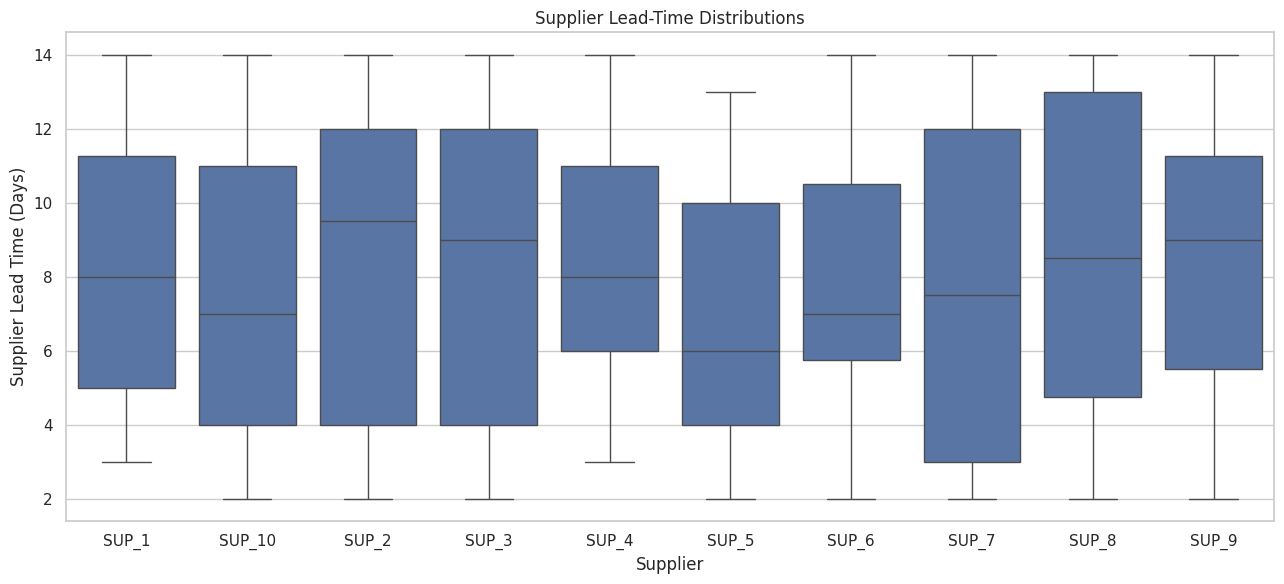

In [33]:

# STEP 6C: VISUALISE SUPPLIER LEAD-TIME DISTRIBUTIONS

# Create a figure for the supplier lead-time boxplots.
plt.figure(figsize=(13, 6))

# Display the distribution of lead times for each supplier.
sns.boxplot(
    data=df_supplier_analysis,
    x="Supplier_ID",
    y="Supplier_Lead_Time_Days",
    order=sorted(df_supplier_analysis["Supplier_ID"].unique())
)

# Add a descriptive title and axis labels.
plt.title("Supplier Lead-Time Distributions")
plt.xlabel("Supplier")
plt.ylabel("Supplier Lead Time (Days)")

# Improve the layout and display the figure.
plt.tight_layout()
plt.show()


In [34]:

# STEP 6D: CREATE A GROUP-LEVEL SUPPLIER DATASET

# Select one record per SKU-warehouse combination.
# Supplier and lead time are constant within each group,
# as established in Step 6B.
df_supplier_group = (
    df_supplier_analysis[
        [
            "SKU_Warehouse_Group",
            "SKU_ID",
            "Warehouse_ID",
            "Supplier_ID",
            "Supplier_Lead_Time_Days",
            "Inventory_Level",
            "Order_Quantity",
            "Units_Sold"
        ]
    ]
    .drop_duplicates(
        subset=["SKU_Warehouse_Group"]
    )
    .reset_index(drop=True)
)

# Confirm the dimensions of the group-level dataset.
print("GROUP-LEVEL SUPPLIER DATASET DIMENSIONS")
print("-" * 55)
print(df_supplier_group.shape)

# Confirm that each SKU-warehouse combination appears once.
print("\nUNIQUE SKU-WAREHOUSE GROUPS")
print("-" * 55)
print(df_supplier_group["SKU_Warehouse_Group"].nunique())

# Examine the number of SKU-warehouse groups assigned to each supplier.
print("\nSKU-WAREHOUSE GROUPS PER SUPPLIER")
print("-" * 55)

display(
    df_supplier_group
    .groupby("Supplier_ID")
    .agg(
        Number_of_SKU_Warehouse_Groups=(
            "SKU_Warehouse_Group", "count"
        ),
        Mean_Lead_Time=(
            "Supplier_Lead_Time_Days", "mean"
        ),
        Minimum_Lead_Time=(
            "Supplier_Lead_Time_Days", "min"
        ),
        Maximum_Lead_Time=(
            "Supplier_Lead_Time_Days", "max"
        ),
        Distinct_Lead_Times=(
            "Supplier_Lead_Time_Days", "nunique"
        )
    )
    .reset_index()
    .round(3)
)

# Check whether any missing values were introduced.
print("\nMISSING VALUES IN GROUP-LEVEL DATASET")
print("-" * 55)
print(df_supplier_group.isna().sum())


GROUP-LEVEL SUPPLIER DATASET DIMENSIONS
-------------------------------------------------------
(250, 8)

UNIQUE SKU-WAREHOUSE GROUPS
-------------------------------------------------------
250

SKU-WAREHOUSE GROUPS PER SUPPLIER
-------------------------------------------------------


,Supplier_ID,Number_of_SKU_Warehouse_Groups,Mean_Lead_Time,Minimum_Lead_Time,Maximum_Lead_Time,Distinct_Lead_Times
0,SUP_1,28,8.107,3,14,12
1,SUP_10,27,7.407,2,14,10
2,SUP_2,26,8.423,2,14,11
3,SUP_3,23,8.261,2,14,12
4,SUP_4,25,8.640,3,14,10
5,SUP_5,23,6.957,2,13,11
6,SUP_6,20,7.900,2,14,11
7,SUP_7,34,7.559,2,14,11
8,SUP_8,28,8.500,2,14,13
9,SUP_9,16,8.188,2,14,12



MISSING VALUES IN GROUP-LEVEL DATASET
-------------------------------------------------------
SKU_Warehouse_Group        0
SKU_ID                     0
Warehouse_ID               0
Supplier_ID                0
Supplier_Lead_Time_Days    0
Inventory_Level            0
Order_Quantity             0
Units_Sold                 0
dtype: int64


In [36]:

# STEP 6F: STATISTICAL COMPARISON OF SUPPLIER LEAD TIMES

# Import the Welch ANOVA function.
from statsmodels.stats.oneway import anova_oneway

# Create a list of lead-time observations for each supplier.
supplier_lead_time_groups = [
    group["Supplier_Lead_Time_Days"].to_numpy()
    for supplier, group in df_supplier_group.groupby("Supplier_ID")
]

# ---------------------------------------------------------
# 1. TEST FOR EQUALITY OF VARIANCES
# ---------------------------------------------------------

# Levene's test evaluates whether supplier groups have
# approximately equal variances.
levene_statistic, levene_p_value = stats.levene(
    *supplier_lead_time_groups,
    center="median"
)

print("LEVENE'S TEST FOR EQUALITY OF VARIANCES")
print("-" * 60)
print(f"Test statistic: {levene_statistic:.6f}")
print(f"P-value: {levene_p_value:.6f}")

# ---------------------------------------------------------
# 2. TEST NORMALITY OF THE ONE-WAY ANOVA RESIDUALS
# ---------------------------------------------------------

# Fit a one-way model to obtain residuals.
supplier_mean_lookup = (
    df_supplier_group
    .groupby("Supplier_ID")["Supplier_Lead_Time_Days"]
    .mean()
)

supplier_residuals = (
    df_supplier_group["Supplier_Lead_Time_Days"]
    - df_supplier_group["Supplier_ID"].map(supplier_mean_lookup)
)

# Apply the Shapiro-Wilk normality test to the residuals.
shapiro_statistic, shapiro_p_value = stats.shapiro(
    supplier_residuals
)

print("\nSHAPIRO-WILK TEST FOR MODEL RESIDUALS")
print("-" * 60)
print(f"Test statistic: {shapiro_statistic:.6f}")
print(f"P-value: {shapiro_p_value:.6f}")

# ---------------------------------------------------------
# 3. CONVENTIONAL ONE-WAY ANOVA
# ---------------------------------------------------------

# Compare the mean lead times across the ten suppliers.
anova_result = stats.f_oneway(
    *supplier_lead_time_groups
)

print("\nCONVENTIONAL ONE-WAY ANOVA")
print("-" * 60)
print(f"F-statistic: {anova_result.statistic:.6f}")
print(f"P-value: {anova_result.pvalue:.10f}")

# ---------------------------------------------------------
# 4. WELCH'S ANOVA
# ---------------------------------------------------------

# Welch's ANOVA allows unequal variances and unequal group sizes.
welch_result = anova_oneway(
    data=df_supplier_group["Supplier_Lead_Time_Days"],
    groups=df_supplier_group["Supplier_ID"],
    use_var="unequal",
    welch_correction=True
)

print("\nWELCH'S ANOVA")
print("-" * 60)
print(f"F-statistic: {welch_result.statistic:.6f}")
print(f"Degrees of freedom: {welch_result.df}")
print(f"P-value: {welch_result.pvalue:.10f}")

# ---------------------------------------------------------
# 5. KRUSKAL-WALLIS TEST
# ---------------------------------------------------------

# The Kruskal-Wallis test compares the rank distributions
# across the independent supplier groups.
kruskal_result = stats.kruskal(
    *supplier_lead_time_groups
)

print("\nKRUSKAL-WALLIS TEST")
print("-" * 60)
print(f"H-statistic: {kruskal_result.statistic:.6f}")
print(f"P-value: {kruskal_result.pvalue:.10f}")

# ---------------------------------------------------------
# 6. SUMMARISE THE TEST RESULTS
# ---------------------------------------------------------

# Organise the statistical test results into one table.
supplier_test_summary = pd.DataFrame({
    "Test": [
        "Levene's Test",
        "Shapiro-Wilk Test",
        "One-Way ANOVA",
        "Welch's ANOVA",
        "Kruskal-Wallis"
    ],
    "Test_Statistic": [
        levene_statistic,
        shapiro_statistic,
        anova_result.statistic,
        welch_result.statistic,
        kruskal_result.statistic
    ],
    "P_Value": [
        levene_p_value,
        shapiro_p_value,
        anova_result.pvalue,
        welch_result.pvalue,
        kruskal_result.pvalue
    ]
})

print("\nCONSOLIDATED SUPPLIER STATISTICAL TEST RESULTS")
print("-" * 75)
display(supplier_test_summary.round(8))


LEVENE'S TEST FOR EQUALITY OF VARIANCES
------------------------------------------------------------
Test statistic: 1.315334
P-value: 0.229409

SHAPIRO-WILK TEST FOR MODEL RESIDUALS
------------------------------------------------------------
Test statistic: 0.947229
P-value: 0.000000

CONVENTIONAL ONE-WAY ANOVA
------------------------------------------------------------
F-statistic: 0.466355
P-value: 0.8962541654

WELCH'S ANOVA
------------------------------------------------------------
F-statistic: 0.497942
Degrees of freedom: (9.0, np.float64(93.13561335805542))
P-value: 0.8724817563

KRUSKAL-WALLIS TEST
------------------------------------------------------------
H-statistic: 4.106598
P-value: 0.9042573582

CONSOLIDATED SUPPLIER STATISTICAL TEST RESULTS
---------------------------------------------------------------------------


,Test,Test_Statistic,P_Value
0,Levene's Test,1.315334,2.294087e-01
1,Shapiro-Wilk Test,0.947229,7.000000e-08
2,One-Way ANOVA,0.466355,8.962542e-01
3,Welch's ANOVA,0.497942,8.724818e-01
4,Kruskal-Wallis,4.106598,9.042574e-01


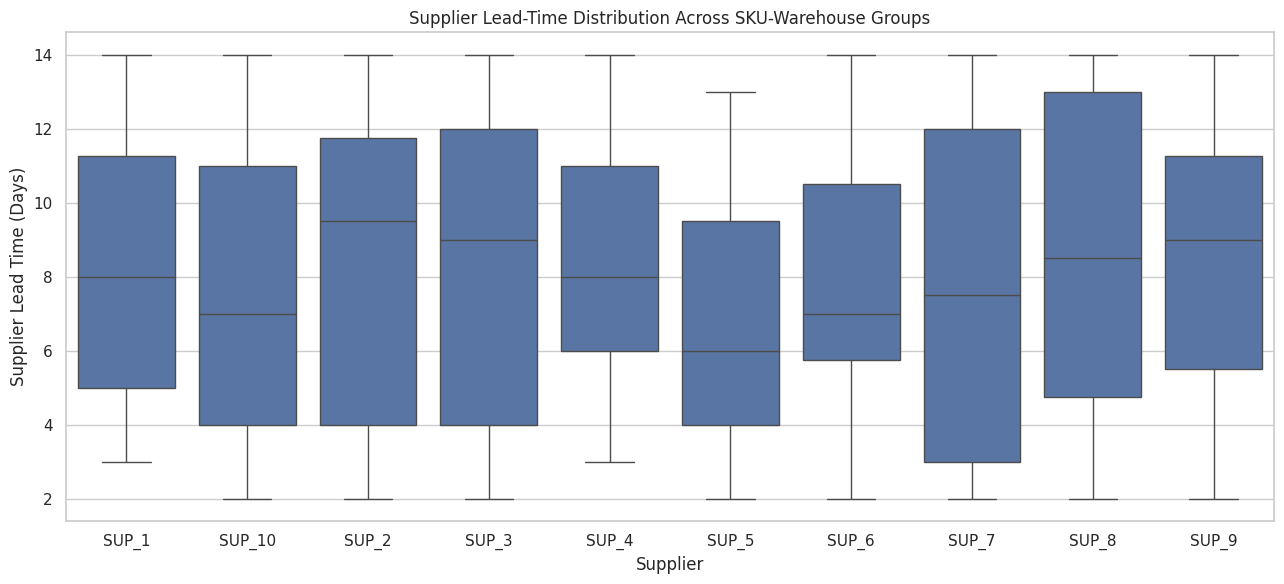

In [35]:

# STEP 6E: VISUALISE GROUP-LEVEL SUPPLIER LEAD TIMES

# Create a figure for the supplier lead-time distributions.
plt.figure(figsize=(13, 6))

# Plot one lead-time observation per SKU-warehouse group.
sns.boxplot(
    data=df_supplier_group,
    x="Supplier_ID",
    y="Supplier_Lead_Time_Days",
    order=sorted(df_supplier_group["Supplier_ID"].unique())
)

# Add descriptive chart labels.
plt.title(
    "Supplier Lead-Time Distribution Across SKU-Warehouse Groups"
)
plt.xlabel("Supplier")
plt.ylabel("Supplier Lead Time (Days)")

# Improve spacing and display the plot.
plt.tight_layout()
plt.show()


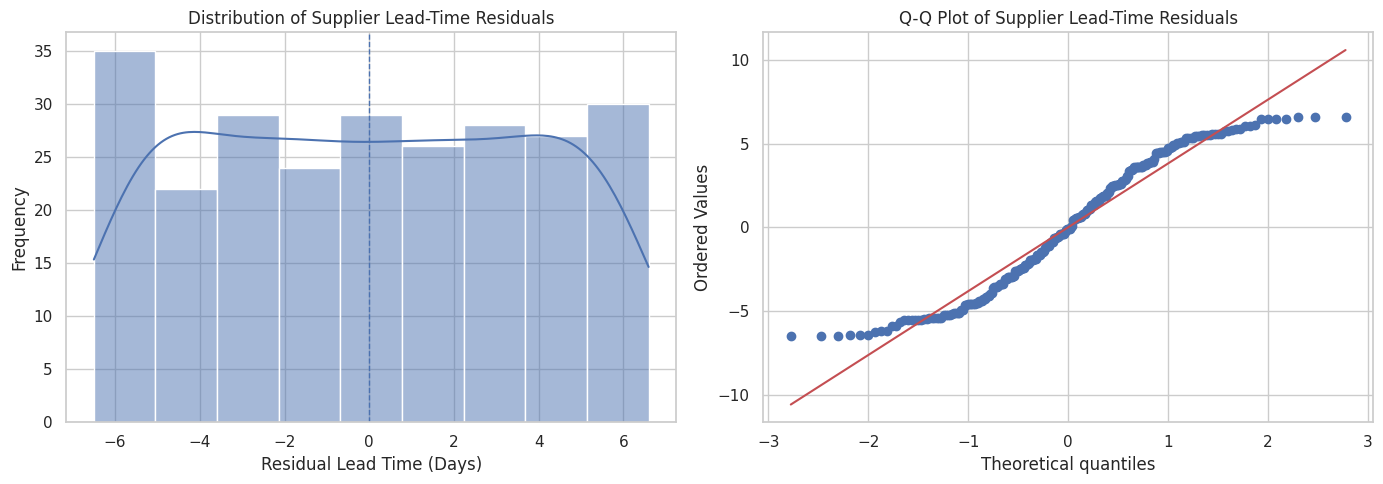

SUPPLIER ALLOCATION ACROSS WAREHOUSES
----------------------------------------------------------------------


Warehouse_ID,WH_1,WH_2,WH_3,WH_4,WH_5
Supplier_ID,,,,,
SUP_1,2,6,7,7,6
SUP_10,4,4,3,5,11
SUP_2,8,6,5,5,2
SUP_3,7,4,3,4,5
SUP_4,4,9,5,4,3
SUP_5,6,2,4,4,7
SUP_6,5,5,3,6,1
SUP_7,4,6,7,10,7
SUP_8,5,5,9,3,6



SUPPLIER ALLOCATION ACROSS SKUS
----------------------------------------------------------------------


SKU_ID,SKU_1,SKU_10,SKU_11,SKU_12,SKU_13,SKU_14,SKU_15,SKU_16,SKU_17,SKU_18,...,SKU_46,SKU_47,SKU_48,SKU_49,SKU_5,SKU_50,SKU_6,SKU_7,SKU_8,SKU_9
Supplier_ID,,,,,,,,,,,,,,,,,,,,,
SUP_1,0,0,0,1,0,2,1,1,1,0,...,0,1,1,0,3,0,0,0,1,1
SUP_10,0,3,0,0,1,0,0,0,1,0,...,1,1,1,2,0,1,1,0,0,1
SUP_2,1,1,0,0,0,2,0,0,0,2,...,0,0,0,0,0,1,0,1,1,0
SUP_3,0,0,1,0,0,1,0,0,0,1,...,1,0,0,1,0,0,2,0,0,1
SUP_4,0,0,1,0,1,0,0,1,1,0,...,0,0,0,1,0,1,0,0,0,0
SUP_5,2,1,0,1,1,0,0,2,0,0,...,1,1,0,1,0,0,0,1,0,0
SUP_6,0,0,0,1,0,0,2,0,0,1,...,0,0,0,0,0,0,0,1,0,0
SUP_7,0,0,1,0,1,0,1,0,1,0,...,1,2,1,0,1,0,1,1,2,1
SUP_8,1,0,1,2,0,0,0,0,1,1,...,1,0,1,0,1,2,0,1,1,0



NUMBER OF DISTINCT SUPPLIERS PER WAREHOUSE
----------------------------------------------------------------------


,Distinct_Suppliers
Warehouse_ID,
WH_1,10
WH_2,10
WH_3,10
WH_4,10
WH_5,10



NUMBER OF DISTINCT SUPPLIERS PER SKU
----------------------------------------------------------------------


,Number_of_SKUs
Supplier_ID,
3,7
4,25
5,18


In [37]:

# STEP 6G: DIAGNOSTIC PLOTS AND SUPPLIER ALLOCATION

# ---------------------------------------------------------
# 1. VISUALISE THE ANOVA RESIDUAL DISTRIBUTION
# ---------------------------------------------------------

# Create a figure containing two diagnostic plots.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot a histogram with a density curve for the residuals.
sns.histplot(
    supplier_residuals,
    kde=True,
    ax=axes[0]
)

# Add a reference line at zero.
axes[0].axvline(
    0,
    linestyle="--",
    linewidth=1
)

# Add titles and labels.
axes[0].set_title("Distribution of Supplier Lead-Time Residuals")
axes[0].set_xlabel("Residual Lead Time (Days)")
axes[0].set_ylabel("Frequency")

# Create a Q-Q plot to assess residual normality.
stats.probplot(
    supplier_residuals,
    dist="norm",
    plot=axes[1]
)

# Add a title to the Q-Q plot.
axes[1].set_title("Q-Q Plot of Supplier Lead-Time Residuals")

# Adjust spacing and display the plots.
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 2. SUPPLIER ALLOCATION ACROSS WAREHOUSES
# ---------------------------------------------------------

# Count the number of SKU-warehouse combinations for each
# supplier and warehouse.
supplier_warehouse_allocation = pd.crosstab(
    df_supplier_group["Supplier_ID"],
    df_supplier_group["Warehouse_ID"]
)

print("SUPPLIER ALLOCATION ACROSS WAREHOUSES")
print("-" * 70)
display(supplier_warehouse_allocation)

# ---------------------------------------------------------
# 3. SUPPLIER ALLOCATION ACROSS SKUS
# ---------------------------------------------------------

# Count the number of warehouse combinations for each
# supplier and SKU.
supplier_sku_allocation = pd.crosstab(
    df_supplier_group["Supplier_ID"],
    df_supplier_group["SKU_ID"]
)

print("\nSUPPLIER ALLOCATION ACROSS SKUS")
print("-" * 70)
display(supplier_sku_allocation)

# ---------------------------------------------------------
# 4. COUNT SUPPLIER REPRESENTATION BY SKU AND WAREHOUSE
# ---------------------------------------------------------

# Count the number of distinct suppliers represented
# within each warehouse.
suppliers_per_warehouse = (
    df_supplier_group
    .groupby("Warehouse_ID")["Supplier_ID"]
    .nunique()
)

print("\nNUMBER OF DISTINCT SUPPLIERS PER WAREHOUSE")
print("-" * 70)
display(suppliers_per_warehouse.to_frame("Distinct_Suppliers"))

# Count the number of distinct suppliers represented
# within each SKU.
suppliers_per_sku = (
    df_supplier_group
    .groupby("SKU_ID")["Supplier_ID"]
    .nunique()
)

print("\nNUMBER OF DISTINCT SUPPLIERS PER SKU")
print("-" * 70)
display(
    suppliers_per_sku
    .value_counts()
    .sort_index()
    .to_frame("Number_of_SKUs")
)


In [38]:

# STEP 6H: AGGREGATE OPERATIONAL MEASURES BY SKU-WAREHOUSE GROUP

# Calculate average operational measures across all daily records
# for each SKU-warehouse combination.
df_operational_group = (
    df_supplier_analysis
    .groupby(
        [
            "SKU_Warehouse_Group",
            "SKU_ID",
            "Warehouse_ID",
            "Supplier_ID"
        ],
        as_index=False
    )
    .agg(
        Supplier_Lead_Time_Days=(
            "Supplier_Lead_Time_Days", "first"
        ),
        Average_Inventory_Level=(
            "Inventory_Level", "mean"
        ),
        Average_Order_Quantity=(
            "Order_Quantity", "mean"
        ),
        Average_Daily_Sales=(
            "Units_Sold", "mean"
        ),
        Daily_Observation_Count=(
            "Units_Sold", "count"
        )
    )
)

# Display the dimensions of the aggregated dataset.
print("OPERATIONAL GROUP DATASET DIMENSIONS")
print("-" * 60)
print(df_operational_group.shape)

# Confirm the number of unique SKU-warehouse combinations.
print("\nUNIQUE SKU-WAREHOUSE GROUPS")
print("-" * 60)
print(df_operational_group["SKU_Warehouse_Group"].nunique())

# Confirm that every group contains 365 daily observations.
print("\nDAILY OBSERVATION COUNT PER GROUP")
print("-" * 60)
display(
    df_operational_group["Daily_Observation_Count"]
    .value_counts()
    .sort_index()
    .to_frame("Number_of_Groups")
)

# Display descriptive statistics for the aggregated variables.
print("\nGROUP-LEVEL OPERATIONAL DESCRIPTIVE STATISTICS")
print("-" * 60)

display(
    df_operational_group[
        [
            "Supplier_Lead_Time_Days",
            "Average_Inventory_Level",
            "Average_Order_Quantity",
            "Average_Daily_Sales"
        ]
    ]
    .describe()
    .round(4)
)


OPERATIONAL GROUP DATASET DIMENSIONS
------------------------------------------------------------
(250, 9)

UNIQUE SKU-WAREHOUSE GROUPS
------------------------------------------------------------
250

DAILY OBSERVATION COUNT PER GROUP
------------------------------------------------------------


,Number_of_Groups
Daily_Observation_Count,
365,250



GROUP-LEVEL OPERATIONAL DESCRIPTIVE STATISTICS
------------------------------------------------------------


,Supplier_Lead_Time_Days,Average_Inventory_Level,Average_Order_Quantity,Average_Daily_Sales
count,250.0000,250.0000,250.0000,250.0000
mean,7.9840,471.5223,19.2725,20.0546
std,3.9157,53.9226,0.6081,0.2572
min,2.0000,374.5342,17.8959,19.4548
25%,4.0000,422.8199,18.8082,19.8795
50%,8.0000,472.2507,19.3000,20.0685
75%,11.0000,514.7644,19.6870,20.2288
max,14.0000,582.2192,21.2548,20.7205


In [39]:

# STEP 6H: CORRELATION ANALYSIS OF SUPPLIER LEAD TIME
# AND GROUP-LEVEL OPERATIONAL OUTCOMES

# Define the operational variables to compare with supplier lead time.
operational_outcomes = [
    "Average_Inventory_Level",
    "Average_Order_Quantity",
    "Average_Daily_Sales"
]

# Create an empty list to store the correlation results.
correlation_results = []

# Calculate Pearson and Spearman correlations for each outcome.
for outcome in operational_outcomes:

    # Calculate Pearson correlation for linear association.
    pearson_result = stats.pearsonr(
        df_operational_group["Supplier_Lead_Time_Days"],
        df_operational_group[outcome]
    )

    # Calculate Spearman correlation for monotonic association.
    spearman_result = stats.spearmanr(
        df_operational_group["Supplier_Lead_Time_Days"],
        df_operational_group[outcome]
    )

    # Store the results.
    correlation_results.append({
        "Operational_Outcome": outcome,
        "Pearson_Correlation": pearson_result.statistic,
        "Pearson_P_Value": pearson_result.pvalue,
        "Spearman_Correlation": spearman_result.statistic,
        "Spearman_P_Value": spearman_result.pvalue
    })

# Convert the results into a dataframe.
operational_correlation_summary = pd.DataFrame(
    correlation_results
)

# Display the correlation results.
print("SUPPLIER LEAD TIME AND OPERATIONAL OUTCOME CORRELATIONS")
print("-" * 90)

display(
    operational_correlation_summary.round(6)
)


SUPPLIER LEAD TIME AND OPERATIONAL OUTCOME CORRELATIONS
------------------------------------------------------------------------------------------


,Operational_Outcome,Pearson_Correlation,Pearson_P_Value,Spearman_Correlation,Spearman_P_Value
0,Average_Inventory_Level,0.033231,0.601016,0.034223,0.590192
1,Average_Order_Quantity,-0.040004,0.528951,-0.041936,0.509237
2,Average_Daily_Sales,0.017957,0.777535,0.008642,0.891848


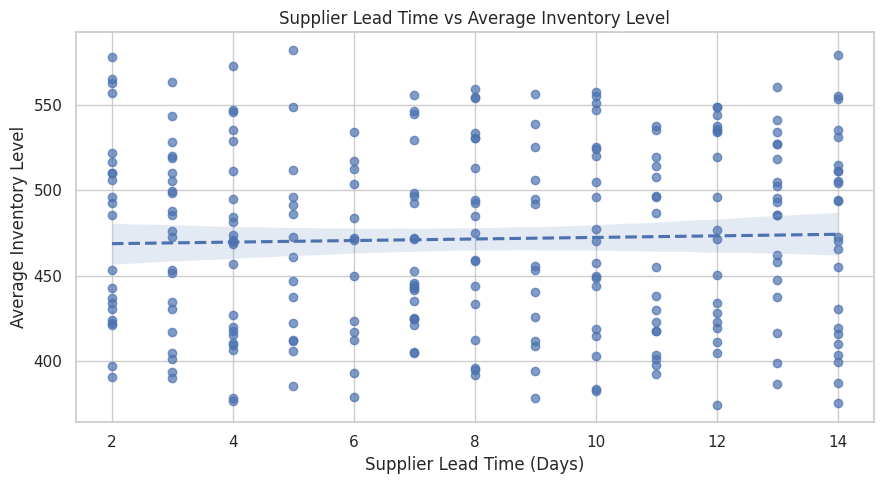

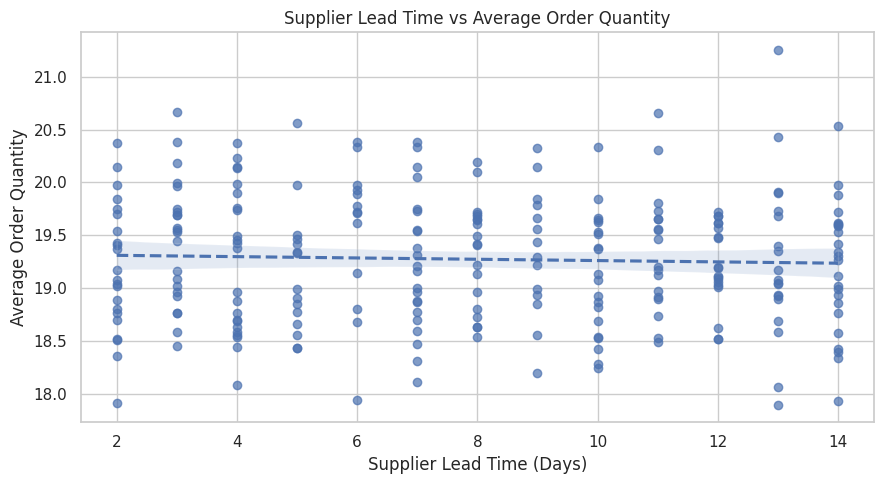

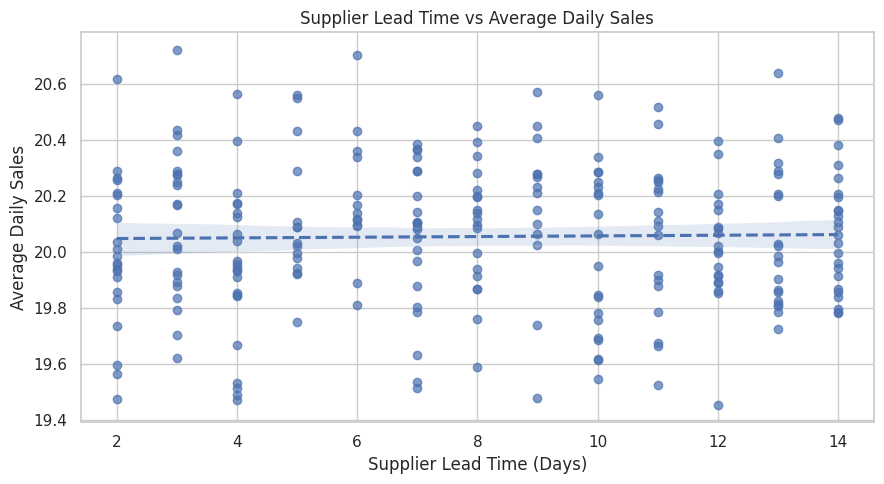

In [40]:

# STEP 6H: VISUALISE SUPPLIER LEAD TIME AND OPERATIONAL OUTCOMES

# Define descriptive titles and axis labels for each outcome.
plot_information = {
    "Average_Inventory_Level": (
        "Supplier Lead Time vs Average Inventory Level",
        "Average Inventory Level"
    ),
    "Average_Order_Quantity": (
        "Supplier Lead Time vs Average Order Quantity",
        "Average Order Quantity"
    ),
    "Average_Daily_Sales": (
        "Supplier Lead Time vs Average Daily Sales",
        "Average Daily Sales"
    )
}

# Create one scatterplot for each operational outcome.
for outcome, (chart_title, y_axis_label) in plot_information.items():

    # Create a separate figure for the outcome.
    plt.figure(figsize=(9, 5))

    # Plot one point per SKU-warehouse combination.
    sns.regplot(
        data=df_operational_group,
        x="Supplier_Lead_Time_Days",
        y=outcome,
        scatter_kws={"alpha": 0.7},
        line_kws={"linestyle": "--"}
    )

    # Add chart labels.
    plt.title(chart_title)
    plt.xlabel("Supplier Lead Time (Days)")
    plt.ylabel(y_axis_label)

    # Adjust the layout and display the chart.
    plt.tight_layout()
    plt.show()


In [41]:

# STEP 6I: FIXED-EFFECTS REGRESSION FOR SUPPLIER LEAD TIME

# Define the three operational outcomes.
operational_outcomes = [
    "Average_Inventory_Level",
    "Average_Order_Quantity",
    "Average_Daily_Sales"
]

# Create dictionaries to store the fitted regression models.
base_regression_results = {}
supplier_adjusted_results = {}

# Create a list to collect the regression summary statistics.
regression_summary_rows = []

# Estimate two models for each operational outcome.
for outcome in operational_outcomes:

    # -----------------------------------------------------
    # MODEL 1: CONTROL FOR SKU AND WAREHOUSE DIFFERENCES
    # -----------------------------------------------------

    # Specify the regression formula.
    base_formula = (
        f"{outcome} ~ Supplier_Lead_Time_Days "
        "+ C(SKU_ID) + C(Warehouse_ID)"
    )

    # Estimate the ordinary least squares model.
    base_model = smf.ols(
        formula=base_formula,
        data=df_operational_group
    )

    # Calculate HC3 heteroskedasticity-robust standard errors.
    base_results = base_model.fit(cov_type="HC3")

    # Store the fitted model.
    base_regression_results[outcome] = base_results

    # Extract the lead-time coefficient and inference statistics.
    base_coefficient = base_results.params[
        "Supplier_Lead_Time_Days"
    ]

    base_p_value = base_results.pvalues[
        "Supplier_Lead_Time_Days"
    ]

    base_confidence_interval = base_results.conf_int().loc[
        "Supplier_Lead_Time_Days"
    ]

    # Add the results to the summary list.
    regression_summary_rows.append({
        "Outcome": outcome,
        "Model": "SKU and Warehouse Fixed Effects",
        "Lead_Time_Coefficient": base_coefficient,
        "HC3_Standard_Error": base_results.bse[
            "Supplier_Lead_Time_Days"
        ],
        "P_Value": base_p_value,
        "CI_Lower": base_confidence_interval.iloc[0],
        "CI_Upper": base_confidence_interval.iloc[1],
        "R_Squared": base_results.rsquared,
        "Observations": int(base_results.nobs)
    })

    # -----------------------------------------------------
    # MODEL 2: ALSO CONTROL FOR SUPPLIER DIFFERENCES
    # -----------------------------------------------------

    # Specify the extended regression formula.
    supplier_formula = (
        f"{outcome} ~ Supplier_Lead_Time_Days "
        "+ C(SKU_ID) + C(Warehouse_ID) + C(Supplier_ID)"
    )

    # Estimate the supplier-adjusted ordinary least squares model.
    supplier_model = smf.ols(
        formula=supplier_formula,
        data=df_operational_group
    )

    # Calculate HC3 heteroskedasticity-robust standard errors.
    supplier_results = supplier_model.fit(cov_type="HC3")

    # Store the fitted model.
    supplier_adjusted_results[outcome] = supplier_results

    # Extract the lead-time coefficient and inference statistics.
    supplier_coefficient = supplier_results.params[
        "Supplier_Lead_Time_Days"
    ]

    supplier_p_value = supplier_results.pvalues[
        "Supplier_Lead_Time_Days"
    ]

    supplier_confidence_interval = supplier_results.conf_int().loc[
        "Supplier_Lead_Time_Days"
    ]

    # Add the extended model results to the summary list.
    regression_summary_rows.append({
        "Outcome": outcome,
        "Model": "SKU, Warehouse and Supplier Fixed Effects",
        "Lead_Time_Coefficient": supplier_coefficient,
        "HC3_Standard_Error": supplier_results.bse[
            "Supplier_Lead_Time_Days"
        ],
        "P_Value": supplier_p_value,
        "CI_Lower": supplier_confidence_interval.iloc[0],
        "CI_Upper": supplier_confidence_interval.iloc[1],
        "R_Squared": supplier_results.rsquared,
        "Observations": int(supplier_results.nobs)
    })

# Convert the collected results into a dataframe.
fixed_effects_regression_summary = pd.DataFrame(
    regression_summary_rows
)

# Display the regression results.
print("SUPPLIER LEAD TIME FIXED-EFFECTS REGRESSION RESULTS")
print("-" * 100)

display(
    fixed_effects_regression_summary.round(6)
)

# ---------------------------------------------------------
# CHECK MODEL MATRIX RANK
# ---------------------------------------------------------

# Check whether the extended models have full column rank.
print("\nSUPPLIER-ADJUSTED MODEL RANK CHECKS")
print("-" * 65)

for outcome, results in supplier_adjusted_results.items():

    print(f"\nOutcome: {outcome}")
    print(f"Model matrix rank: {results.model.rank}")
    print(f"Number of model columns: {results.model.exog.shape[1]}")
    print(f"Model degrees of freedom: {results.df_model:.0f}")


SUPPLIER LEAD TIME FIXED-EFFECTS REGRESSION RESULTS
----------------------------------------------------------------------------------------------------


,Outcome,Model,Lead_Time_Coefficient,HC3_Standard_Error,P_Value,CI_Lower,CI_Upper,R_Squared,Observations
0,Average_Inventory_Level,SKU and Warehouse Fixed Effects,0.090186,1.103117,0.934841,-2.071885,2.252256,0.237757,250
1,Average_Inventory_Level,"SKU, Warehouse and Supplier Fixed Effects",0.237010,1.156742,0.837654,-2.030162,2.504182,0.280743,250
2,Average_Order_Quantity,SKU and Warehouse Fixed Effects,-0.008328,0.013815,0.546645,-0.035405,0.018750,0.223172,250
3,Average_Order_Quantity,"SKU, Warehouse and Supplier Fixed Effects",-0.010661,0.014620,0.465881,-0.039316,0.017994,0.271608,250
4,Average_Daily_Sales,SKU and Warehouse Fixed Effects,-0.002969,0.005495,0.588994,-0.013739,0.007801,0.211434,250
5,Average_Daily_Sales,"SKU, Warehouse and Supplier Fixed Effects",-0.004488,0.005862,0.443939,-0.015977,0.007001,0.232657,250



SUPPLIER-ADJUSTED MODEL RANK CHECKS
-----------------------------------------------------------------

Outcome: Average_Inventory_Level
Model matrix rank: 64
Number of model columns: 64
Model degrees of freedom: 63

Outcome: Average_Order_Quantity
Model matrix rank: 64
Number of model columns: 64
Model degrees of freedom: 63

Outcome: Average_Daily_Sales
Model matrix rank: 64
Number of model columns: 64
Model degrees of freedom: 63


### Research Question 3: Supplier Lead Time and Operational Outcomes

#### Research objective

The third research question investigated whether supplier lead time was associated with differences in inventory levels, replenishment quantities and daily sales.

The analysis was conducted at the SKU-warehouse combination level because supplier assignment and supplier lead time were constant within each of the 250 combinations.

#### Data preparation

The original dataset contained 91,250 daily observations across 250 SKU-warehouse combinations. Each combination contained 365 daily observations.

Daily operational measures were aggregated into group-level averages:

- Average inventory level
- Average replenishment quantity
- Average daily sales

Supplier lead time was retained as a group-level characteristic. This produced an analytical dataset of 250 observations.

#### Descriptive correlation analysis

Pearson and Spearman correlation tests were conducted to examine the relationships between supplier lead time and the three operational outcomes.

The results were:

| Operational outcome | Pearson correlation | Pearson p-value | Spearman correlation | Spearman p-value |
|---|---:|---:|---:|---:|
| Average inventory level | 0.033231 | 0.601016 | 0.034223 | 0.590192 |
| Average order quantity | -0.040004 | 0.528951 | -0.041936 | 0.509237 |
| Average daily sales | 0.017957 | 0.777535 | 0.008642 | 0.891848 |

All six correlation coefficients were close to zero, and none was statistically significant at the 5% level.

These findings indicate very weak observed linear and monotonic associations in the group-level data.

#### Fixed-effects regression analysis

Fixed-effects regression models were estimated for each operational outcome.

Two specifications were considered:

1. SKU and warehouse fixed effects.
2. SKU, warehouse and supplier fixed effects.

HC3 heteroskedasticity-robust standard errors were used.

The estimated supplier lead-time coefficients were:

| Outcome | Model | Coefficient | p-value |
|---|---|---:|---:|
| Average inventory level | SKU and warehouse fixed effects | 0.090186 | 0.934841 |
| Average inventory level | SKU, warehouse and supplier fixed effects | 0.237010 | 0.837654 |
| Average order quantity | SKU and warehouse fixed effects | -0.008328 | 0.546645 |
| Average order quantity | SKU, warehouse and supplier fixed effects | -0.010661 | 0.465881 |
| Average daily sales | SKU and warehouse fixed effects | -0.002969 | 0.588994 |
| Average daily sales | SKU, warehouse and supplier fixed effects | -0.004488 | 0.443939 |

None of the six lead-time coefficients was statistically significant at the 5% level. All corresponding 95% confidence intervals included zero.

#### Model specification checks

The supplier-adjusted model design matrices had a rank of 64, equal to the number of columns, with 63 model degrees of freedom.

This indicates that the estimated design matrices did not exhibit exact linear dependence.

However, full matrix rank does not establish that the models capture every relevant source of confounding or dependence.

#### Research conclusion

The correlation and fixed-effects regression results consistently indicate that supplier lead time was not significantly associated with average inventory levels, average replenishment quantities or average daily sales in this dataset.

The estimated relationships were weak, and all regression confidence intervals included zero.

Consequently, the null hypotheses of no adjusted association were not rejected for the three operational outcomes.

These findings should not be interpreted as evidence that supplier lead time is operationally unimportant. The analysis uses observational, aggregated data, and the dataset does not establish the timing of actual purchase orders, goods receipts or supplier delivery events.

The findings therefore describe the relationships observed in this dataset and do not establish causal effects.

In [42]:

# STEP 6I: COMPARE FIXED-EFFECTS MODEL SPECIFICATIONS

# Define the three operational outcomes.
supplier_model_outcomes = [
    "Average_Inventory_Level",
    "Average_Order_Quantity",
    "Average_Daily_Sales"
]

# Store the model specifications for comparison.
supplier_model_formulas = {
    "SKU and Warehouse FE": (
        "C(SKU_ID) + C(Warehouse_ID)"
    ),
    "SKU, Warehouse and Supplier FE": (
        "C(SKU_ID) + C(Warehouse_ID) + C(Supplier_ID)"
    )
}

# Store the comparison results.
supplier_model_comparison = []

# Estimate each outcome under both specifications.
for outcome in supplier_model_outcomes:

    for model_name, fixed_effects in supplier_model_formulas.items():

        # Construct the regression formula.
        formula = (
            f"{outcome} ~ Supplier_Lead_Time_Days + "
            f"{fixed_effects}"
        )

        # Estimate the ordinary least-squares model.
        model = smf.ols(
            formula=formula,
            data=df_operational_group
        ).fit(
            cov_type="HC3"
        )

        # Extract the lead-time coefficient and its uncertainty.
        supplier_model_comparison.append({
            "Outcome": outcome,
            "Model": model_name,
            "Lead_Time_Coefficient": (
                model.params["Supplier_Lead_Time_Days"]
            ),
            "HC3_Standard_Error": (
                model.bse["Supplier_Lead_Time_Days"]
            ),
            "P_Value": (
                model.pvalues["Supplier_Lead_Time_Days"]
            ),
            "CI_Lower": (
                model.conf_int().loc[
                    "Supplier_Lead_Time_Days", 0
                ]
            ),
            "CI_Upper": (
                model.conf_int().loc[
                    "Supplier_Lead_Time_Days", 1
                ]
            ),
            "R_Squared": model.rsquared,
            "Adjusted_R_Squared": model.rsquared_adj
        })

# Convert the comparison results into a dataframe.
supplier_model_comparison = pd.DataFrame(
    supplier_model_comparison
)

# Display the model comparison.
print("SUPPLIER LEAD-TIME MODEL COMPARISON")
print("-" * 100)

display(
    supplier_model_comparison.round(6)
)


SUPPLIER LEAD-TIME MODEL COMPARISON
----------------------------------------------------------------------------------------------------


,Outcome,Model,Lead_Time_Coefficient,HC3_Standard_Error,P_Value,CI_Lower,CI_Upper,R_Squared,Adjusted_R_Squared
0,Average_Inventory_Level,SKU and Warehouse FE,0.090186,1.103117,0.934841,-2.071885,2.252256,0.237757,0.026674
1,Average_Inventory_Level,"SKU, Warehouse and Supplier FE",0.237010,1.156742,0.837654,-2.030162,2.504182,0.280743,0.037124
2,Average_Order_Quantity,SKU and Warehouse FE,-0.008328,0.013815,0.546645,-0.035405,0.018750,0.223172,0.008051
3,Average_Order_Quantity,"SKU, Warehouse and Supplier FE",-0.010661,0.014620,0.465881,-0.039316,0.017994,0.271608,0.024895
4,Average_Daily_Sales,SKU and Warehouse FE,-0.002969,0.005495,0.588994,-0.013739,0.007801,0.211434,-0.006938
5,Average_Daily_Sales,"SKU, Warehouse and Supplier FE",-0.004488,0.005862,0.443939,-0.015977,0.007001,0.232657,-0.027250


### Step 6I: Supplier Lead-Time Model Stability and Explanatory Power

Two fixed-effects specifications were compared for each operational outcome to assess the stability of the estimated supplier lead-time coefficients.

The first specification included SKU and warehouse fixed effects. The second additionally included supplier fixed effects.

#### Coefficient stability

The estimated lead-time coefficients changed only modestly between the two specifications:

- Average inventory level: 0.090186 to 0.237010.
- Average order quantity: -0.008328 to -0.010661.
- Average daily sales: -0.002969 to -0.004488.

All six lead-time coefficients remained statistically insignificant at the 5% level. Their confidence intervals included zero.

The absence of statistically significant associations was therefore consistent across the two specifications.

#### Explanatory power

The adjusted R-squared values were relatively low:

| Outcome | SKU and warehouse FE | Additional supplier FE |
|---|---:|---:|
| Average inventory level | 0.026674 | 0.037124 |
| Average order quantity | 0.008051 | 0.024895 |
| Average daily sales | -0.006938 | -0.027250 |

The models explained relatively little variation in the aggregated operational outcomes after accounting for model complexity.

The negative adjusted R-squared values for average daily sales indicate that these specifications did not outperform an intercept-only benchmark under the adjusted R-squared criterion.

#### Interpretation and limitations

Adding supplier indicators did not materially change the estimated lead-time relationships or produce statistically significant coefficients.

However, supplier assignments were fixed within SKU-warehouse combinations. The models therefore use separate SKU and warehouse indicators rather than a complete set of SKU-warehouse fixed effects alongside supplier indicators.

HC3 robust standard errors were used. These account for heteroskedasticity but do not explicitly address all possible dependence among observations sharing SKUs or warehouses.

These results should consequently be interpreted as exploratory adjusted associations rather than causal estimates.

**Conclusion:** The supplier lead-time estimates were relatively stable across the two specifications, but there was insufficient evidence of an association with average inventory, replenishment quantity or daily sales.

In [43]:
# STEP 7A: FINAL VALIDATION OF THE STATISTICAL ANALYSIS DATASETS

# Create a list to store the validation results.
validation_results = []

# Define a helper function to record whether each validation passes.
def record_check(check_name, condition, details):
    validation_results.append({
        "Validation_Check": check_name,
        "Passed": bool(condition),
        "Details": details
    })

# 1. Confirm that the original analytical dataset has the expected dimensions.
record_check(
    "Original dataset dimensions",
    df.shape == (91250, 15),
    f"Observed dimensions: {df.shape}"
)

# 2. Confirm that the original dataset has no missing values.
record_check(
    "Original dataset missing values",
    df.isna().sum().sum() == 0,
    f"Total missing values: {df.isna().sum().sum()}"
)

# 3. Confirm that the original dataset has no duplicate complete records.
record_check(
    "Original dataset duplicate records",
    df.duplicated().sum() == 0,
    f"Duplicate records: {df.duplicated().sum()}"
)

# 4. Confirm that the promotion analysis contains all original observations.
record_check(
    "Promotion analysis observation count",
    len(df_promotion_analysis) == 91250,
    f"Observations: {len(df_promotion_analysis)}"
)

# 5. Confirm that the promotion analysis includes both promotion categories.
promotion_categories = sorted(
    df_promotion_analysis["Promotion_Flag"].dropna().unique().tolist()
)

record_check(
    "Promotion analysis category variation",
    promotion_categories == [0, 1],
    f"Observed categories: {promotion_categories}"
)

# 6. Confirm that the inventory analysis excludes only the first
#    observation from each of the 250 SKU-Warehouse groups.
record_check(
    "Inventory analysis observation count",
    len(df_inventory_valid) == 91000,
    f"Valid observations: {len(df_inventory_valid)}"
)

# 7. Confirm that the beginning inventory proxy has no missing values
#    in the valid inventory analysis dataset.
record_check(
    "Beginning inventory proxy completeness",
    df_inventory_valid["Beginning_Inventory_Proxy"].isna().sum() == 0,
    (
        "Missing proxy values: "
        f"{df_inventory_valid['Beginning_Inventory_Proxy'].isna().sum()}"
    )
)

# 8. Confirm that the supplier operational dataset has 250 groups.
record_check(
    "Supplier operational group count",
    len(df_operational_group) == 250,
    f"Operational groups: {len(df_operational_group)}"
)

# 9. Confirm that each operational group contains 365 daily observations.
record_check(
    "Supplier operational group observation counts",
    df_operational_group["Daily_Observation_Count"].eq(365).all(),
    (
        "Groups with 365 observations: "
        f"{df_operational_group['Daily_Observation_Count'].eq(365).sum()}"
    )
)

# 10. Confirm that the stockout flag remains constant in the original data.
stockout_categories = sorted(
    df["Stockout_Flag"].dropna().unique().tolist()
)

record_check(
    "Stockout flag limitation retained",
    stockout_categories == [0],
    f"Observed Stockout_Flag categories: {stockout_categories}"
)

# Convert the validation results into a readable DataFrame.
final_validation = pd.DataFrame(validation_results)

# Display all validation results.
print("FINAL NOTEBOOK 03 VALIDATION")
print("=" * 70)
display(final_validation)

# Display the overall validation outcome.
print("\nVALIDATION SUMMARY")
print("=" * 70)
print("Checks passed:", final_validation["Passed"].sum())
print("Total checks:", len(final_validation))
print("All checks passed:", final_validation["Passed"].all())

FINAL NOTEBOOK 03 VALIDATION


,Validation_Check,Passed,Details
0,Original dataset dimensions,True,"Observed dimensions: (91250, 15)"
1,Original dataset missing values,True,Total missing values: 0
2,Original dataset duplicate records,True,Duplicate records: 0
3,Promotion analysis observation count,True,Observations: 91250
4,Promotion analysis category variation,True,"Observed categories: [0, 1]"
5,Inventory analysis observation count,True,Valid observations: 91000
6,Beginning inventory proxy completeness,True,Missing proxy values: 0
7,Supplier operational group count,True,Operational groups: 250
8,Supplier operational group observation counts,True,Groups with 365 observations: 250
9,Stockout flag limitation retained,True,Observed Stockout_Flag categories: [0]



VALIDATION SUMMARY
Checks passed: 10
Total checks: 10
All checks passed: True


# Final Statistical Analysis: Research Scope and Validation

## Research Questions

This notebook investigated three research questions:

1. Is promotion status associated with differences in daily units sold?
2. Is beginning inventory associated with daily sales?
3. Is supplier lead time associated with inventory levels, replenishment quantities, and daily sales?

## Analytical Approach

The investigation used descriptive statistics, visual exploration, correlation analysis, hypothesis testing, and regression modelling.

Where appropriate, the analysis accounted for repeated observations and differences across SKU-warehouse combinations and dates. Robust standard errors were used to improve statistical inference under potential dependence and heteroskedasticity.

## Important Data and Methodological Limitations

- The dataset contains 91,250 daily observations covering 365 dates from 1 January to 30 December 2024.
- The dataset contains 250 SKU-warehouse combinations.
- The `Stockout_Flag` variable is constant at zero and therefore cannot support meaningful stockout classification or modelling.
- The previous day's recorded inventory was used as a proxy for beginning inventory. Its exact physical timing relative to replenishment and sales is not verified.
- Supplier lead time is constant within each SKU-warehouse combination, so the supplier analysis relies on between-group variation.
- The supplied demand forecasts were evaluated, but their original forecasting methodology and forecast horizon were not available.
- The analysis is observational. Statistical associations should not be interpreted as proof of causation.
- Statistical significance does not necessarily imply operational or commercial importance.

## Reproducibility

The original dataset was retained, and analytical datasets were prepared separately for the research questions. Data transformations, statistical methods, model specifications, and validation checks are documented within this notebook.


# Final Statistical Analysis: Research Findings and Conclusions

## 1. Research Question 1: Promotion Status and Daily Sales

**Research question:** Is promotion status associated with differences in daily units sold?

### Main findings

- Average daily sales without promotion: 19.51 units.
- Average daily sales during promotion: 24.91 units.
- Descriptive difference: approximately 5.41 additional units during promotion observations.
- The daily fixed-effects regression estimated a promotion coefficient of approximately 5.40.
- Two-way cluster-robust standard error: approximately 0.140.
- Finite-cluster t-test p-value: approximately 3.09 × 10⁻¹⁰⁷.
- 95% confidence interval: approximately [5.125, 5.675].

### Conclusion

Promotion status was positively and statistically significantly associated with daily units sold after controlling for SKU-warehouse group and daily fixed effects.

The estimated association was approximately 5.40 additional units sold per observation during promotion periods.

This is an observational association, not evidence that promotions caused the increase. Promotion allocation may be related to other factors that were not observed or controlled for in this dataset.

---

## 2. Research Question 2: Beginning Inventory and Daily Sales

**Research question:** Is beginning inventory associated with daily units sold?

### Main findings

- The previous day's recorded inventory was used as a proxy for beginning inventory.
- Valid observations: 91,000.
- Pooled Pearson correlation: approximately -0.039.
- Pooled Spearman correlation: approximately -0.039.
- Fixed-effects regression coefficient: approximately -0.000196.
- Two-way cluster-robust standard error: approximately 0.000169.
- Finite-cluster t-test p-value: approximately 0.249.
- 95% confidence interval: approximately [-0.000530, 0.000138].

### Conclusion

The pooled correlations indicated a very weak negative relationship between the beginning inventory proxy and daily sales.

However, after controlling for SKU-warehouse group and date fixed effects, the estimated coefficient was very small and not statistically significant at the 5% significance level.

The analysis therefore did not find sufficient evidence of an adjusted association between the beginning inventory proxy and daily sales under the specified model.

The proxy is based on the previous day's recorded inventory. Its exact timing relative to daily replenishment and sales has not been independently verified.

---

## 3. Research Question 3: Supplier Lead Time and Operational Outcomes

**Research question:** Is supplier lead time associated with inventory levels, replenishment quantities, and daily sales?

### Main findings

The supplier analysis was conducted at SKU-warehouse group level, producing 250 operational observations.

Supplier lead time was constant within each SKU-warehouse combination. Consequently, the analysis relied on variation between operational groups.

The supplier-adjusted regression models produced the following results:

| Operational outcome | Lead-time coefficient | HC3 standard error | p-value |
|---|---:|---:|---:|
| Average inventory level | 0.237010 | 1.156742 | 0.837654 |
| Average order quantity | -0.010661 | 0.014620 | 0.465881 |
| Average daily sales | -0.004488 | 0.005862 | 0.443939 |

All three p-values exceeded 0.05, and all three confidence intervals included zero.

The supplier-level comparisons also did not show statistically significant differences in average lead time.

### Conclusion

The analysis did not find statistically significant evidence of an association between supplier lead time and the three operational outcomes under the specified models.

The results should be interpreted cautiously because lead time varies between operational groups rather than within individual SKU-warehouse combinations. The models also do not establish causal effects.

---

## 4. Overall Research Findings

The three research questions produced different statistical results:

1. Promotion status showed a positive and statistically significant adjusted association with daily sales.
2. The beginning inventory proxy did not show a statistically significant adjusted association with daily sales.
3. Supplier lead time did not show statistically significant adjusted associations with average inventory, average order quantity, or average daily sales.

The results demonstrate the importance of distinguishing descriptive patterns, statistical associations, and causal relationships.

A statistically significant result does not automatically establish causation or commercial importance. Likewise, a non-significant result does not prove that no relationship exists.

---

## 5. Methodological and Data Limitations

The following limitations apply to this investigation:

- The dataset contains 91,250 daily observations covering 365 dates from 1 January to 30 December 2024.
- The dataset contains 50 SKUs, 5 warehouses, 10 suppliers, 4 regions, and 250 SKU-warehouse combinations.
- The `Stockout_Flag` variable contains only zeros. It cannot support meaningful stockout classification or predictive modelling in its current form.
- The previous day's `Inventory_Level` was used as a proxy for beginning inventory. Its precise physical timing relative to replenishment and sales is unknown.
- Supplier lead time is constant within each SKU-warehouse combination, limiting the available source of variation for supplier analysis.
- The original demand forecasting methodology and forecast horizon were not provided.
- The analysis is observational and cannot independently establish causation.
- One calendar year's observations are insufficient to establish recurring annual seasonality.
- Regression results depend on the selected model specifications and their assumptions.
- Two-way cluster-robust inference and finite-cluster approximations have limitations, particularly when the number of clusters in one dimension is relatively small.

---

## 6. Reproducibility and Validation

The final validation stage confirmed that all 10 validation checks passed.

The checks covered:

- Original dataset dimensions.
- Missing values and duplicate records.
- Promotion analysis observation count and category variation.
- Valid beginning inventory observations.
- Completeness of the beginning inventory proxy.
- Number of supplier operational groups.
- Daily observation counts per group.
- Retention of the constant `Stockout_Flag` limitation.

**Validation result: 10 out of 10 checks passed.**

The original dataset was preserved, while separate analytical datasets were created for the individual research questions.

The notebook documents the data preparation, analytical methods, statistical tests, model specifications, results, and limitations.
